# 미션 9_cGAN 패션 이미지 생성

FashionMNIST 10개 클래스를 **원하는 클래스로 골라 생성**하는 조건부 GAN(cGAN). 제공 코드를 기준선으로 고정하고, 판별자 · 정규화 · 손실 · 옵티마이저 · 증강 · 생성자 구조 · 에폭 수를 **한 번에 한 가지씩** 바꾸며 검증 지표로 개선.

<img src="images/m9_map.png" alt="미션 9 학습 지도: 준비부터 test 평가까지 6단계" width="726">

**단계별 구성**: 한글 요약 → 실행 흐름 → 코드(이유 주석) → 실행 결과 → 결과 해설 → 소속별 최종 요약표

## 🎯 학습 목표

이 미션을 마치면 다음을 직접 할 수 있어야 함

1. 클래스 분포 · 밝기 · 형태 · 방향 · 중복을 탐색해 **생성 모델이 배워야 할 것과 쓰면 안 되는 증강**을 미리 판단한다
2. 생성 이미지를 FID · IS · 조건 일치율 · precision · recall로 재고, **실제끼리(바닥) · 잡음(천장) 기준선**으로 숫자를 읽는다
3. 제공 cGAN의 생성자 · 판별자 구조를 설명하고, Projection 판별자 · Spectral Norm · Hinge 손실 · 넓은 생성자를 직접 구현한다
4. 한 번에 한 가지만 바꾸는 실험과 **seed 반복**으로, 개선이 진짜인지 운인지 구분한다
5. 클래스별 혼동 · 다양성 · 학습 데이터 외우기까지 점검해 남은 약점을 수치로 설명한다

## 🧭 활용처

- **패션 · 커머스**: 카테고리를 지정해 상품 시안 · 썸네일 후보를 대량으로 만들고, 같은 잡음으로 스타일을 유지한 채 종류만 바꿈
- **데이터 증강**: 수가 적은 클래스의 학습 이미지를 클래스 조건으로 보충 (외우기 점검을 통과한 생성기만 사용)
- **생성 모델 평가 일반**: 이미지 · 음성 · 텍스트 생성에서 '사실성(precision)과 다양성(recall)'을 나눠 보고 기준선과 비교하는 방법

## 핵심 결과

- **최종 모델**: Projection 판별자 + 넓은 생성자 · BCE · Adam(2e-4, 0.5 · 0.999) · 80 epoch, test FID(Inception) **15.53** · FID(분류기) **0.342** · 조건 일치율 **0.940**
- **제공 코드 대비 (같은 test · 같은 잡음)**: FID(Inception) 25.01 → 15.53 (**-37.9%**) · FID(분류기) 1.230 → 0.342 (**-72.2%**) · recall 0.311 → 0.478 · **6개 지표 모두 개선**
- **가장 큰 한 걸음은 판별자 조건 방식**: 클래스 숫자 1개 → Projection(내적)으로 검증 FID(분류기) 1.230 → 0.544
- **표준 기법이 늘 좋진 않음**: Spectral Norm · Hinge · betas (0, 0.9) · TTUR 모두 이 설정에서는 나빠짐, 이유를 판별자 정답률 곡선으로 확인
- **좌우 반전 증강은 해로움**: EDA에서 신발이 한 방향(Sneaker 99.4%)임을 확인 → 반전하자 생성 신발 절반이 뒤집히고 조건 일치율 0.93 → 0.82
- **seed 하나로는 결론 불가**: seed 42에서는 B가 1위였지만 seed 3개 평균에서 넓은 생성자 G가 1위 (0.533 vs 0.612)
- **mode collapse · 외우기 없음**: 클래스 안 다양성 0.88 이상, 학습 이미지에 붙은 비율 0.4% (실제 test 1.0%)
- **재현성**: 전체 노트북을 두 번 실행해 모든 학습 결과가 소수점 넷째 자리까지 같음
- **제공 코드 보완**: 손실 출력만 → **검증 · 시험 분리 + 6개 지표 + 기준선**, 고정 학습 → **5 epoch마다 검증해 최고 시점 복원**, `BatchNorm2d(64, 0.8)`의 0.8은 momentum이 아니라 eps 자리라는 점을 4-1에서 명시

**평가 기준**: 모델 선택은 **검증 FID(분류기)** (FashionMNIST로 학습한 판정 분류기의 특징 128개로 계산, 낮을수록 좋음). Inception FID · IS · 조건 일치율 · precision · recall은 함께 보고, test는 5장에서 한 번만 사용.

### 데이터 구성

- **출처**: torchvision `FashionMNIST` (Zalando 상품 이미지, 첫 실행 때 약 30MB 내려받기)
- **이미지**: 28×28 흑백, train 60,000 · test 10,000, 클래스마다 6,000 · 1,000장으로 균등
- **클래스 10개**: T-shirt/top · Trouser · Pullover · Dress · Coat · Sandal · Shirt · Sneaker · Bag · Ankle boot
- **분할**: train에서 클래스마다 600장을 떼어 검증 6,000, 나머지 학습 54,000 · 공식 test 10,000은 최종 평가 한 번
- **평가 모델**: 직접 학습한 판정 분류기(검증 정확도 0.931) · ImageNet Inception v3 (첫 실행 약 104MB)
- **실행 환경**: RTX 3060에서 GAN 학습 14회 합계 약 86분

---
## 0. 준비

### 0-1. 환경 설정

**한글 요약**

데이터 · 모델 · 평가 라이브러리를 불러오고, 한글 폰트 · seed · 학습 장치 지정. GPU 합성곱도 같은 값을 내도록 cuDNN 결정적 모드 사용.

**실행 흐름**

1. **입력**: 설치된 라이브러리 · 폰트 목록
2. **처리**: OpenMP 충돌 방지 → 라이브러리 불러오기 → 한글 폰트 지정 → 난수 고정 함수 정의
3. **저장**: `SEED` · `set_seed` · `device` · `DATA_DIR`
4. **출력**: 학습 장치 · 라이브러리 버전

In [1]:
# 실행 환경
import os  # 환경 변수 설정
# Windows Anaconda의 OpenMP 중복 로드 충돌 방지
os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")

# 라이브러리 불러오기
import copy                                             # 최고 성능 시점 가중치 보관
import random                                           # 파이썬 난수 고정
import time                                             # 학습 시간 측정
from pathlib import Path                                # 운영체제와 무관한 경로 처리
import matplotlib.pyplot as plt                         # 그래프 · 이미지 출력
import numpy as np                                      # 배열 계산
import pandas as pd                                     # 결과 표 정리
import torch                                            # 텐서 · GPU 연산
import torch.nn as nn                                   # 모델 층 · 손실 함수
import torch.nn.functional as F                         # 손실 · 크기 변경 · 이동 증강
import torchvision                                      # FashionMNIST · Inception
from IPython.display import display                     # 셀 중간 표 출력
from matplotlib import font_manager                     # 설치된 한글 폰트 탐색
from torch.utils.data import DataLoader, TensorDataset  # 배치 단위 데이터 공급

# 그래프 스타일
installed_fonts = {f.name for f in font_manager.fontManager.ttflist}  # 설치된 폰트 이름 집합
for font in ["Malgun Gothic", "AppleGothic", "NanumGothic"]:  # Windows → macOS → Linux 순서로 탐색
    if font in installed_fonts:                               # 처음 찾은 한글 폰트 사용
        plt.rcParams["font.family"] = font                    # 그래프 한글 깨짐 방지
        break                                                 # 하나만 적용
plt.rcParams["axes.unicode_minus"] = False                    # 한글 폰트의 마이너스 기호 깨짐 방지


# 난수 고정
def set_seed(seed):                   # 난수 4종을 한 번에 고정
    random.seed(seed)                 # 파이썬 난수
    np.random.seed(seed)              # 분할 · 배열 난수
    torch.manual_seed(seed)           # 가중치 초기값 · 잡음
    torch.cuda.manual_seed_all(seed)  # GPU 난수


# 기본 설정
SEED = 42                                                # 분할 · 학습 재현 기준값
set_seed(SEED)                                           # 노트북 시작 시 한 번 고정
torch.backends.cudnn.benchmark = False                   # 매번 같은 합성곱 알고리즘 선택
torch.backends.cudnn.deterministic = True                # GPU 합성곱도 매번 같은 값
device = "cuda" if torch.cuda.is_available() else "cpu"  # GPU가 있으면 GPU 학습
DATA_DIR = Path.home() / ".cache" / "torchvision_data"   # 데이터 저장 위치 (저장소 밖)
# 학습 장치 확인
print("device:", device, "|", torch.cuda.get_device_name(0) if device == "cuda" else "CPU")
print("torch", torch.__version__, "| torchvision", torchvision.__version__)  # 재현용 버전 기록

device: cuda | NVIDIA GeForce RTX 3060
torch 2.11.0+cu128 | torchvision 0.26.0+cu128


**결과 해설**

```
device: cuda | RTX 3060        : GPU 학습
torch 2.11 · torchvision 0.26  : CUDA 12.8 빌드, FashionMNIST · Inception v3 모두 torchvision에서 불러옴
```

cuDNN 결정적 모드 덕분에 같은 코드를 두 번 실행해도 모든 학습 결과가 소수점 넷째 자리까지 같았음 (마무리의 재현성 확인).

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| manual_seed() · cuda.manual_seed_all()<br>backends.cudnn.deterministic · benchmark<br>cuda.is_available() · cuda.get_device_name() | torch | CPU · GPU 난수 고정<br>GPU 합성곱 결과 고정<br>GPU 여부 · 이름 | `torch.manual_seed(seed)`<br>`torch.backends.cudnn.deterministic = True`<br>`torch.cuda.get_device_name(0)` |
| seed() | random · numpy.random | 파이썬 · NumPy 난수 고정 | `random.seed(seed)` · `np.random.seed(seed)` |
| fontManager.ttflist<br>rcParams | matplotlib | 설치된 폰트 목록<br>그래프 전역 설정 | `font_manager.fontManager.ttflist`<br>`plt.rcParams["font.family"] = font` |
| Path.home() · / 연산 | pathlib | 사용자 폴더 · 경로 결합 | `Path.home() / ".cache" / "torchvision_data"` |
| environ.setdefault() | os | 없을 때만 환경 변수 설정 | `os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")` |
| set_seed() | 사용자 정의 함수 | 난수 4종을 한 번에 고정 | `set_seed(SEED)` |
| print() | Python 내장 함수 | 장치 · 버전 출력 | `print("device:", device, ...)` |
| import · from<br>조건 표현식<br>for · if · break | Python 기본 문법 | 라이브러리 불러오기<br>GPU 있으면 "cuda"<br>한글 폰트 탐색 후 중단 | `import torch.nn as nn`<br>`"cuda" if ... else "cpu"`<br>`for font in [...]:` |

---
## 1. 데이터 탐색

### 1-1. 데이터 구성과 클래스 분포

**한글 요약**

- torchvision에서 FashionMNIST를 내려받아 크기 · 자료형 · 픽셀 범위 확인
- 클래스별 장수를 세어 불균형 보정이 필요한지 판단
- 클래스마다 10장씩 보며 클래스 안 모양 차이와 헷갈릴 만한 클래스 확인

**실행 흐름**

1. **입력**: `DATA_DIR` (첫 실행 때 약 30MB 내려받기)
2. **처리**: train · test 불러오기 → 클래스별 장수 표 → 10 × 10 예시
3. **저장**: `X_all` · `y_all` · `X_test` · `y_test` · `CLASSES`
4. **출력**: 크기 · 범위 · 클래스 분포 표 · 예시 이미지

train (60000, 28, 28) torch.uint8 | test (10000, 28, 28)
픽셀 범위 0 ~ 255


클래스,T-shirt/top,Trouser,Pullover,Dress,Coat,Sandal,Shirt,Sneaker,Bag,Ankle boot
train,6000,6000,6000,6000,6000,6000,6000,6000,6000,6000
test,1000,1000,1000,1000,1000,1000,1000,1000,1000,1000


✅ 통과: 클래스마다 train 6,000장 · test 1,000장


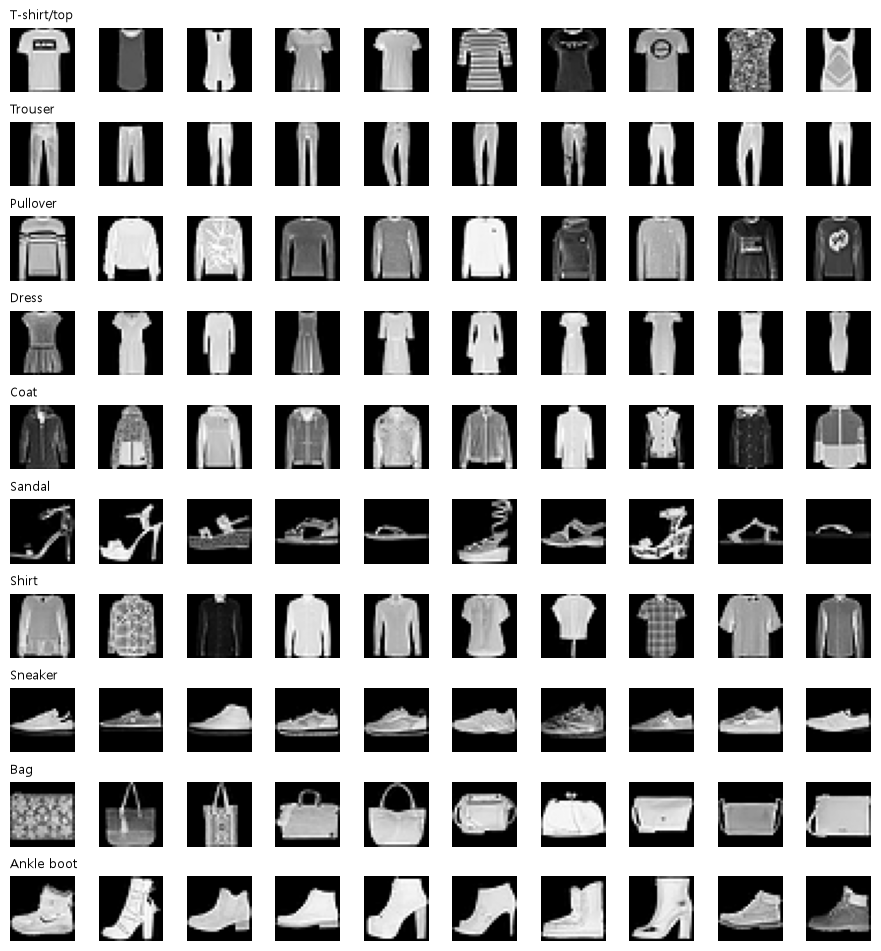

In [2]:
# 원본 데이터 (첫 실행만 내려받기)
# 학습용 60,000장
train_raw = torchvision.datasets.FashionMNIST(DATA_DIR, train=True, download=True)
# 시험용 10,000장
test_raw = torchvision.datasets.FashionMNIST(DATA_DIR, train=False, download=True)
X_all, y_all = train_raw.data, train_raw.targets  # (60000, 28, 28) uint8 · (60000,) int64
X_test, y_test = test_raw.data, test_raw.targets  # (10000, 28, 28) · (10000,)
CLASSES = train_raw.classes                       # 클래스 이름 10개 (번호 순서)
print("train", tuple(X_all.shape), X_all.dtype, "| test", tuple(X_test.shape))  # 크기 · 자료형
print("픽셀 범위", X_all.min().item(), "~", X_all.max().item())  # 0 ~ 255 흑백

# 클래스 분포
counts = pd.DataFrame({"클래스": CLASSES,  # 클래스별 train · test 장수 표
                       "train": np.bincount(y_all.numpy(), minlength=10),  # 클래스별 장수
                       "test": np.bincount(y_test.numpy(), minlength=10)})
display(counts.set_index("클래스").T)                                      # 클래스가 열
assert counts["train"].nunique() == 1 and counts["test"].nunique() == 1    # 모든 클래스 같은 장수
print("✅ 통과: 클래스마다 train 6,000장 · test 1,000장")                  # 불균형 보정 불필요

# 클래스별 예시
fig, axes = plt.subplots(10, 10, figsize=(9, 9.6))            # 10클래스 × 10장
for c in range(10):                                           # 클래스마다 한 행
    idx = torch.where(y_all == c)[0][:10]                     # 클래스 c의 앞 10장
    for k, i in enumerate(idx):                               # 열 번호 · 이미지 번호
        axes[c, k].imshow(X_all[i], cmap="gray")              # 흑백 표시
        axes[c, k].axis("off")                                # 눈금 숨김
    axes[c, 0].set_title(CLASSES[c], loc="left", fontsize=9)  # 행 이름
plt.tight_layout()                                            # 제목 겹침 방지
plt.show()                                                    # 그림 출력

**결과 해설**

```
train (60000, 28, 28) uint8 · test 10000  : 28×28 흑백, 픽셀 0 ~ 255 정수
클래스마다 train 6,000 · test 1,000       : 완전히 균등 → 클래스 가중치 · 재표집 불필요
```

예시를 보면 같은 클래스 안에서도 모양 차이가 큼: T-shirt/top에 민소매 · 무늬 · 글자, Sandal에 하이힐 · 납작한 샌들, Bag에 손잡이 있는 가방 · 클러치가 섞임. 생성자는 클래스마다 **여러 모양**을 만들어야 함 → 5-4에서 클래스 안 다양성을 따로 측정.

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| datasets.FashionMNIST(train=, download=)<br>.data · .targets · .classes | torchvision | 데이터 내려받기 · 불러오기<br>이미지 · 클래스 · 이름 | `torchvision.datasets.FashionMNIST(DATA_DIR, train=True, download=True)`<br>`train_raw.data` · `train_raw.classes` |
| where() · min() · max() | torch | 조건 위치 · 최솟값 · 최댓값 | `torch.where(y_all == c)[0][:10]` |
| bincount(minlength=) | numpy | 클래스별 개수 | `np.bincount(y_all.numpy(), minlength=10)` |
| DataFrame() · set_index() · T<br>nunique() | pandas | 분포 표 · 클래스를 열로<br>값 종류 수 | `counts.set_index("클래스").T`<br>`counts["train"].nunique() == 1` |
| subplots() · imshow() · axis("off")<br>set_title() · tight_layout() | matplotlib | 격자 · 흑백 표시 · 눈금 숨김<br>행 이름 · 간격 정리 | `plt.subplots(10, 10, ...)` · `imshow(X_all[i], cmap="gray")`<br>`set_title(CLASSES[c], loc="left")` |
| display() | IPython.display | 셀 중간 표 출력 | `display(counts.set_index("클래스").T)` |
| assert | Python 기본 문법 | 균등 분포 확인 | `assert counts["train"].nunique() == 1 ...` |

### 1-2. 밝기와 클래스별 평균 이미지

**한글 요약**

- 이미지마다 평균 밝기와 물체 픽셀 비율(밝기 > 0.1)을 구해 클래스별로 비교
- 클래스별 **평균 이미지**(전형적인 모양)와 **표준편차 이미지**(모양이 자주 바뀌는 곳)를 나란히 확인
- 생성 모델이 무엇을 배워야 하는지(실루엣 · 질감 · 무늬) 미리 파악

**실행 흐름**

1. **입력**: `X_all` · `y_all`
2. **처리**: 0 ~ 1 변환 → 이미지별 밝기 · 물체 비율 → 클래스별 평균 · 표준편차 이미지
3. **저장**: `X01` (0 ~ 1 이미지)
4. **출력**: 클래스별 통계 표 · 평균 / 표준편차 이미지

평균 밝기         물체 비율       
              mean    std   mean    std
클래스                                    
T-shirt/top  0.326  0.113  0.533  0.082
Trouser      0.223  0.057  0.331  0.064
Pullover     0.377  0.128  0.608  0.084
Dress        0.259  0.084  0.393  0.087
Coat         0.385  0.104  0.565  0.079
Sandal       0.137  0.062  0.253  0.089
Shirt        0.332  0.130  0.578  0.093
Sneaker      0.168  0.050  0.287  0.055
Bag          0.354  0.113  0.535  0.118
Ankle boot   0.301  0.072  0.435  0.070

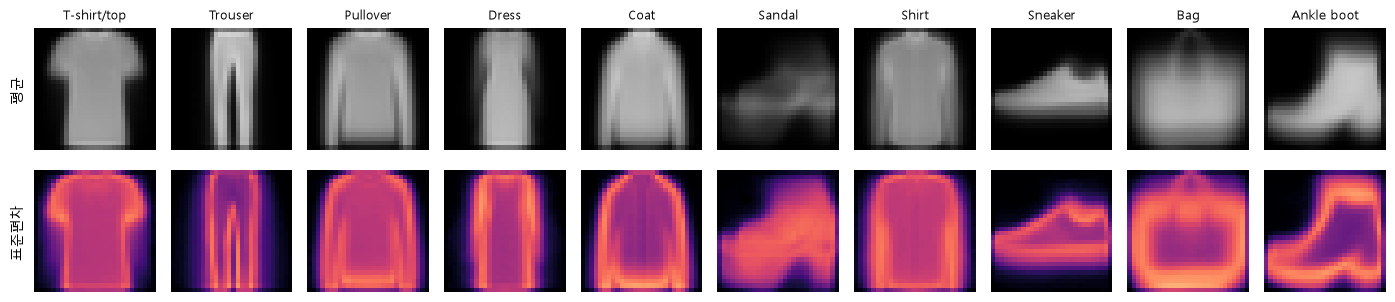

In [3]:
# 이미지별 밝기 통계 (0 ~ 1 범위)
X01 = X_all.float() / 255                        # 픽셀을 0 ~ 1로
mean_bright = X01.mean(dim=(1, 2))               # 이미지 평균 밝기
on_ratio = (X01 > 0.1).float().mean(dim=(1, 2))  # 물체 픽셀 비율 (배경 0 제외)
class_col = pd.Categorical([CLASSES[c] for c in y_all], categories=CLASSES)  # 클래스 번호 순서 유지
# 이미지마다 클래스 · 밝기 · 물체 비율
stats = pd.DataFrame({"클래스": class_col, "평균 밝기": mean_bright.numpy(), "물체 비율": on_ratio.numpy()})
# 클래스별 평균 · 편차
display(stats.groupby("클래스", observed=True).agg(["mean", "std"]).round(3))

# 클래스별 평균 · 표준편차 이미지
fig, axes = plt.subplots(2, 10, figsize=(14, 3.3))                  # 위: 평균 · 아래: 표준편차
for c in range(10):                                                 # 클래스마다 한 열
    imgs = X01[y_all == c]                                          # 클래스 c 6,000장
    axes[0, c].imshow(imgs.mean(0), cmap="gray", vmin=0, vmax=1)    # 평균 = 전형적인 모양
    axes[1, c].imshow(imgs.std(0), cmap="magma", vmin=0, vmax=0.5)  # 표준편차 = 모양이 다양한 곳
    axes[0, c].set_title(CLASSES[c], fontsize=9)                    # 열 이름
    for ax in axes[:, c]:                                           # 위 · 아래 두 칸
        ax.axis("off")                                              # 눈금 숨김
axes[0, 0].text(-6, 14, "평균", rotation=90, va="center")           # 행 이름
axes[1, 0].text(-6, 14, "표준편차", rotation=90, va="center")       # 행 이름
plt.tight_layout()                                                  # 간격 정리
plt.show()                                                          # 그림 출력

**결과 해설**

```
평균 밝기 Coat 0.385 · Pullover 0.377 · Bag 0.354  : 넓고 밝은 상의 · 가방
평균 밝기 Sandal 0.137 · Sneaker 0.168            : 물체가 작아 검은 배경이 대부분
물체 비율 Pullover 0.608 ~ Sandal 0.253           : 클래스마다 화면을 채우는 정도가 2배 이상 차이
밝기 표준편차 Shirt 0.130 · Pullover 0.128         : 같은 클래스 안에서도 밝기가 가장 들쭉날쭉
```

평균 이미지에서 T-shirt/top · Pullover · Coat · Shirt는 실루엣이 거의 같고 소매 길이만 다름. 표준편차 이미지는 상의 4종에서 **테두리(소매 · 어깨)**가, Sandal에서 **전체 영역**이 밝음 → 상의는 윤곽, 샌들은 끈 모양 자체가 이미지마다 크게 바뀜. Sandal 평균 이미지가 가장 흐린 이유.

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| float() · mean(dim=) · std()<br>불리언 비교 > · 인덱싱 | torch | 실수 변환 · 평균 · 표준편차<br>물체 픽셀 · 클래스별 선택 | `X01.mean(dim=(1, 2))` · `imgs.std(0)`<br>`(X01 > 0.1)` · `X01[y_all == c]` |
| Categorical(categories=)<br>groupby(observed=True) · agg(["mean", "std"]) · round() | pandas | 클래스 번호 순서 유지<br>클래스별 평균 · 편차 · 반올림 | `pd.Categorical([...], categories=CLASSES)`<br>`stats.groupby("클래스", observed=True).agg(["mean", "std"])` |
| imshow(cmap=, vmin=, vmax=)<br>text(rotation=) | matplotlib | 같은 색 범위로 표시<br>세로 행 이름 | `imshow(imgs.std(0), cmap="magma", vmin=0, vmax=0.5)`<br>`text(-6, 14, "평균", rotation=90, ...)` |
| 리스트 컴프리헨션 | Python 기본 문법 | 클래스 번호 → 이름 | `[CLASSES[c] for c in y_all]` |

### 1-3. 물체 크기 · 위치 · 좌우 방향

**한글 요약**

- 물체 상자의 가로 폭 · 세로 높이 · 가로 무게중심 · 가장자리에 닿는 비율로 물체가 화면을 얼마나 채우는지 확인 (자르기 · 회전 증강의 위험)
- 왼쪽 절반 밝기 비율과 좌우 비대칭 점수로 **좌우 반전 증강이 데이터 분포를 바꾸는지** 판단
- 신발 3종(Sandal · Sneaker · Ankle boot)을 반전한 모습과 비교

**실행 흐름**

1. **입력**: `X01` · `y_all`
2. **처리**: 물체 마스크 → 폭 · 높이 · 무게중심 · 가장자리 → 왼쪽 밝기 비율 · 좌우 비대칭 → 클래스별 평균
3. **저장**: `shape_table` (4-8에서 생성 이미지와 비교)
4. **출력**: 클래스별 형태 표 · 신발 반전 예시

,가로 폭,세로 높이,가로 무게중심,가장자리 닿음,왼쪽 밝기 비율,좌우 비대칭,왼쪽이 더 무거운 비율
클래스,,,,,,,
T-shirt/top,21.741,27.746,13.697,0.994,0.489,0.251,0.339
Trouser,11.676,27.947,13.787,0.998,0.486,0.424,0.216
Pullover,21.207,27.793,13.643,0.988,0.495,0.242,0.406
Dress,14.683,27.899,13.691,0.998,0.485,0.311,0.343
Coat,20.106,27.823,13.682,0.992,0.490,0.223,0.353
Sandal,27.812,16.128,15.693,0.996,0.374,1.130,0.081
Shirt,21.463,27.709,13.685,0.990,0.490,0.291,0.349
Sneaker,27.854,13.406,15.672,0.993,0.362,0.773,0.006
Bag,25.564,23.343,13.796,0.996,0.488,0.313,0.334


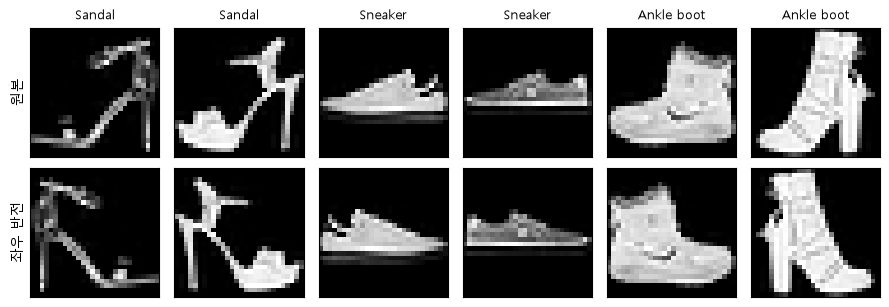

In [4]:
# 물체 상자 · 무게중심 · 좌우 방향
cols = torch.arange(28).float()                          # 가로 좌표 0 ~ 27
mask = X01 > 0.1                                         # 물체 픽셀
has_col, has_row = mask.any(1), mask.any(2)              # 열 · 행마다 물체 존재
width = has_col.sum(1).float()                           # 물체 가로 폭 (열 수)
height = has_row.sum(1).float()                          # 물체 세로 높이 (행 수)
mass = X01.sum(dim=(1, 2))                               # 밝기 총합
cx = (X01.sum(1) * cols).sum(1) / mass                   # 가로 무게중심
left_ratio = X01[:, :, :14].sum(dim=(1, 2)) / mass       # 왼쪽 절반 밝기 비율 (0.5 = 좌우 균형)
asym = (X01 - X01.flip(2)).abs().sum(dim=(1, 2)) / mass  # 좌우 반전과 다른 정도 (0 = 대칭)
# 바깥 1px에 닿음
edge = mask[:, 0].any(1) | mask[:, -1].any(1) | mask[:, :, 0].any(1) | mask[:, :, -1].any(1)
# 이미지마다 형태 통계
shape = pd.DataFrame({"클래스": class_col, "가로 폭": width.numpy(), "세로 높이": height.numpy(),
                      "가로 무게중심": cx.numpy(), "가장자리 닿음": edge.float().numpy(),
                      "왼쪽 밝기 비율": left_ratio.numpy(), "좌우 비대칭": asym.numpy()}).astype({"가로 폭": float})
shape["왼쪽이 더 무거운 비율"] = (shape["왼쪽 밝기 비율"] > 0.5).astype(float)  # 이미지마다 0 · 1
# 클래스별 평균 (비율)
shape_table = shape.groupby("클래스", observed=True).mean().astype(float).round(3)
display(shape_table)                                     # 클래스별 형태 통계

# 신발 3종의 좌우 반전 예시
fig, axes = plt.subplots(2, 6, figsize=(9, 3.2))  # 위: 원본 · 아래: 좌우 반전
for k, c in enumerate([5, 5, 7, 7, 9, 9]):        # Sandal · Sneaker · Ankle boot 2장씩
    img = X01[torch.where(y_all == c)[0][k % 2]]  # 클래스 c의 0 · 1번째
    axes[0, k].imshow(img, cmap="gray")           # 원본
    axes[1, k].imshow(img.flip(1), cmap="gray")   # 좌우 반전
    axes[0, k].set_title(CLASSES[c], fontsize=9)  # 클래스 이름
for ax in axes.ravel():                           # 모든 칸
    ax.set_xticks([])                             # 눈금 숨김
    ax.set_yticks([])                             # 눈금 숨김
axes[0, 0].set_ylabel("원본")                     # 행 이름
axes[1, 0].set_ylabel("좌우 반전")                # 행 이름
plt.tight_layout()                                # 간격 정리
plt.show()                                        # 그림 출력

**결과 해설**

```
가장자리 닿음 0.988 ~ 0.998           : 거의 모든 물체가 28×28 테두리에 닿음 → 자르기 · 확대 증강은 물체를 잘라냄
상의 세로 높이 27.7 ~ 27.9            : 상의 · 바지 · 원피스는 위아래를 꽉 채움
왼쪽이 더 무거운 비율 Sneaker 0.006 · Ankle boot 0.000 · Sandal 0.081 : 신발은 거의 모두 같은 방향
상의 · 바지 · 원피스 · 가방 0.216 ~ 0.406 : 좌우 대칭에 가까움 (좌우 비대칭 0.22 ~ 0.42)
신발 좌우 비대칭 0.77 ~ 1.13           : 상의(0.22 ~ 0.31)의 3 ~ 5배
```

FashionMNIST의 신발은 **밝기(무게)가 오른쪽에 몰린 방향**(왼쪽 밝기 비율 0.28 ~ 0.37)으로 거의 고정. 그림 아래 행처럼 반전하면 데이터에 없는 방향의 신발이 생김 → 좌우 반전 증강은 '흔한 증강'이지만 이 데이터에서는 분포를 바꿀 위험 → 4-8에서 직접 검증.

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| arange() · any() · sum()<br>flip() · abs() | torch | 좌표 · 행 · 열별 물체 존재 · 합<br>좌우 반전 · 차이 크기 | `torch.arange(28)` · `mask.any(1)` · `X01.sum(dim=(1, 2))`<br>`(X01 - X01.flip(2)).abs()` |
| 논리합 연산 (텐서) | torch | 네 변 중 하나라도 닿음 | `mask[:, 0].any(1) ... mask[:, :, -1].any(1)` |
| groupby(observed=True).mean() · astype() | pandas | 클래스별 평균 · 자료형 변환 | `shape.groupby("클래스", observed=True).mean().astype(float)` |
| enumerate() · round() | Python 내장 함수 | 번호와 값 · 반올림 | `enumerate([5, 5, 7, 7, 9, 9])` · `round(..., 3)` |
| set_xticks([]) · set_yticks([]) · set_ylabel() | matplotlib | 눈금 숨김 · 행 이름 (원본 · 좌우 반전) | `axes[1, 0].set_ylabel("좌우 반전")` |

### 1-4. 클래스 간 유사도와 train · test 중복

**한글 요약**

- 클래스 평균 이미지끼리 코사인 유사도를 구해 **생성 · 판정에서 헷갈릴 클래스 쌍**을 미리 찾음
- 픽셀이 완전히 같은 이미지(train 안, train ↔ test)와 **거의 같은 이미지**(가장 가까운 train까지 거리 < 1.0)를 셈
- test가 train의 복사본이면 FID 기준선과 '외우기' 점검이 왜곡되므로 먼저 확인

**실행 흐름**

1. **입력**: `X01` · `X_test`
2. **처리**: 클래스 평균 → 정규화 → 유사도 행렬 → 바이트 비교로 완전 중복 → GPU 거리 계산으로 근접 중복
3. **저장**: 없음 (확인용)
4. **출력**: 비슷한 클래스 쌍 · 중복 수 · 유사도 히트맵

가장 비슷한 클래스 쌍:
  Coat         ↔ Shirt        0.987
  Pullover     ↔ Coat         0.984
  Pullover     ↔ Shirt        0.983
  T-shirt/top  ↔ Shirt        0.949
  Sandal       ↔ Ankle boot   0.927


train 안 완전 중복: 0 장
test 중 train과 완전히 같은 이미지: 0 장


가장 가까운 train 거리 중앙값: 3.46
거리 < 1.0 (거의 같은 이미지): 16 장 (0.16%) · 클래스 일치 16


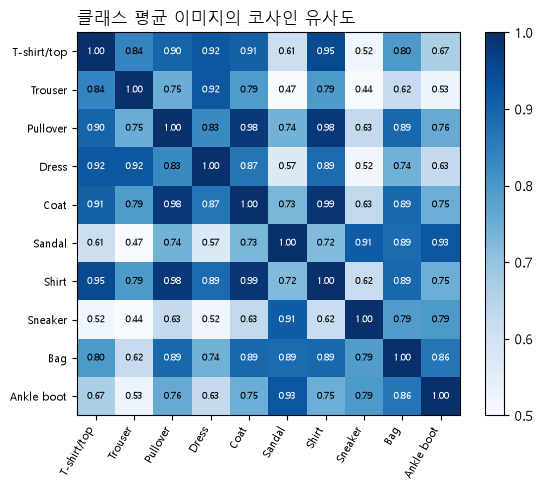

In [5]:
# 클래스 평균 이미지끼리의 코사인 유사도
means = torch.stack([X01[y_all == c].mean(0).flatten() for c in range(10)])  # (10, 784)
means = F.normalize(means, dim=1)                # 길이 1로
sim = (means @ means.T).numpy()                  # 10×10 유사도
# 서로 다른 쌍
pairs = [(sim[i, j], CLASSES[i], CLASSES[j]) for i in range(10) for j in range(i + 1, 10)]
print("가장 비슷한 클래스 쌍:")                  # 생성 · 판정에서 헷갈릴 후보
for s, a, b in sorted(pairs, reverse=True)[:5]:  # 상위 5쌍
    print(f"  {a:<12} ↔ {b:<12} {s:.3f}")        # 유사도 높은 순

# train 안 · train ↔ test 완전 중복 (픽셀이 모두 같은 이미지)
train_keys = {bytes(x.numpy()) for x in X_all}                    # train 이미지 바이트 집합
print("train 안 완전 중복:", len(X_all) - len(train_keys), "장")  # 같은 이미지가 두 번 이상
# train에도 있는 test 이미지 수
print("test 중 train과 완전히 같은 이미지:", sum(bytes(x.numpy()) in train_keys for x in X_test), "장")

# train ↔ test 거의 같은 이미지 (가장 가까운 train까지 거리)
A = X01.flatten(1).to(device)                           # train (60000, 784)
nearest = []  # test 이미지마다 가장 가까운 train 거리 · 번호
for i in range(0, len(X_test), 1000):                   # GPU 메모리에 맞게 1,000장씩
    B = (X_test[i:i + 1000].float() / 255).flatten(1).to(device)  # test 1,000장씩
    nearest.append(torch.cdist(B, A).min(1))            # 유클리드 거리 최솟값 · 위치
near_d = torch.cat([n.values for n in nearest]).cpu()   # (10000,)
near_i = torch.cat([n.indices for n in nearest]).cpu()  # 가장 가까운 train 번호
same_label = (y_all[near_i] == y_test)                  # 가장 가까운 이미지와 클래스가 같은지
print("가장 가까운 train 거리 중앙값:", round(near_d.median().item(), 2))  # 보통 이미지끼리 거리
# 근접 중복 수 · 비율 · 클래스 일치
print("거리 < 1.0 (거의 같은 이미지):", int((near_d < 1).sum()), "장",
      f"({(near_d < 1).float().mean().item():.2%}) · 클래스 일치", int(same_label[near_d < 1].sum()))
del A                                                   # GPU 메모리 반환

# 유사도 행렬 그림
fig, ax = plt.subplots(figsize=(6, 5))                                  # 정사각 히트맵
im = ax.imshow(sim, cmap="Blues", vmin=0.5, vmax=1)                     # 진할수록 비슷
ax.set_xticks(range(10), CLASSES, rotation=60, ha="right", fontsize=8)  # 가로 이름
ax.set_yticks(range(10), CLASSES, fontsize=8)                           # 세로 이름
for i in range(10):                                                     # 행
    for j in range(10):                                                 # 열
        # 칸 숫자 (진한 칸은 흰 글자)
        ax.text(j, i, f"{sim[i, j]:.2f}", ha="center", va="center", fontsize=6.5,
                color="white" if sim[i, j] > 0.85 else "black")         # 칸 숫자
plt.colorbar(im, fraction=0.046)                                        # 색 막대
ax.set_title("클래스 평균 이미지의 코사인 유사도", loc="left")          # 그래프 제목
plt.tight_layout()                                                      # 간격 정리
plt.show()                                                              # 그림 출력

**결과 해설**

```
Coat ↔ Shirt 0.987 · Pullover ↔ Coat 0.984 · Pullover ↔ Shirt 0.983 : 상의끼리 평균 모양이 거의 같음
Sandal ↔ Ankle boot 0.927                                         : 신발끼리도 비슷
train 안 · train ↔ test 완전 중복 0장                              : 같은 파일 복사 없음
거리 < 1.0 근접 중복 16장 (0.16%) · 16장 모두 클래스 같음           : 무시해도 될 수준
```

생성 · 판정에서 헷갈릴 클래스는 **Shirt · Coat · Pullover · T-shirt/top** → 5-2에서 생성 이미지의 클래스 일치도 이 클래스들이 낮을 것으로 예상. test가 train의 복사본이 아니므로 test를 FID 기준과 5-4 외우기 점검의 비교군으로 써도 됨.

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| stack() · flatten() · T · @<br>cdist() · min(1) · median()<br>cat() | torch | 평균 이미지 쌓기 · 펼치기 · 행렬곱<br>거리 행렬 · 최솟값과 위치 · 중앙값<br>조각 결과 이어 붙이기 | `torch.stack([...])` · `means @ means.T`<br>`torch.cdist(B, A).min(1)`<br>`torch.cat([n.values for n in nearest])` |
| normalize(dim=) | torch.nn.functional | 길이 1 정규화 (코사인 유사도) | `F.normalize(means, dim=1)` |
| set · bytes() · sum()<br>sorted(reverse=) · len() | Python 내장 함수 | 바이트 집합으로 완전 중복<br>유사도 큰 순 · 개수 | `{bytes(x.numpy()) for x in X_all}`<br>`sorted(pairs, reverse=True)[:5]` |
| set_xticks(labels, rotation=) · colorbar() | matplotlib | 축 이름 · 색 막대 | `ax.set_xticks(range(10), CLASSES, rotation=60, ...)` |
| del | Python 기본 문법 | GPU 메모리 반환 | `del A` |

---
## 2. 데이터 준비

### 2-1. 학습 · 검증 · 시험 분할과 정규화

**한글 요약**

- train 60,000장을 클래스마다 600장씩 떼어 **검증 6,000장**, 나머지 54,000장을 학습에 사용
- 검증은 실험 비교 · 모델 선택에, 공식 test 10,000장은 **5장 최종 평가에서 한 번만** 사용
- 픽셀을 [-1, 1]로 바꿔 생성자 마지막 Tanh 출력 범위와 맞춤 (배치 크기는 제공 코드의 64 유지)

<img src="images/m9_split.png" alt="학습 · 검증 · 시험 분할과 각 용도" width="837">

**실행 흐름**

1. **입력**: `X_all` · `y_all` · `X_test`
2. **처리**: 클래스별 600장 무작위 선택 → 나머지 학습 → [-1, 1] 변환 → TensorDataset
3. **저장**: `X_train` · `X_val` · `X_te` · `train_ds` · `BATCH`
4. **출력**: 분할 크기 · 값 범위 · 배치 모양 · 점검 결과

In [6]:
# train 60,000장 → 학습 54,000 · 검증 6,000 (클래스 비율 유지)
rng = np.random.default_rng(SEED)                         # 분할 난수
# 검증 번호
val_idx = np.concatenate([rng.choice(np.where(y_all.numpy() == c)[0], 600, replace=False)
                          for c in range(10)])            # 클래스마다 600장
train_idx = np.setdiff1d(np.arange(len(X_all)), val_idx)  # 나머지 54,000장


# [-1, 1] 정규화 (생성자 마지막 Tanh 범위와 맞춤)
def to_tensor(x_uint8):                                # uint8 → [-1, 1] 텐서
    return (x_uint8.float() / 127.5 - 1).unsqueeze(1)  # (N, 1, 28, 28)


X_train, y_train = to_tensor(X_all[train_idx]), y_all[train_idx]  # GAN · 분류기 학습
X_val, y_val = to_tensor(X_all[val_idx]), y_all[val_idx]          # 실험 비교 · 선택
X_te, y_te = to_tensor(X_test), y_test                            # 마지막에 한 번만 사용
BATCH = 64                                                        # 제공 코드의 배치 크기 유지
train_ds = TensorDataset(X_train, y_train)                        # (이미지, 클래스) 쌍

# 점검
# 분할 크기
print("학습", tuple(X_train.shape), "| 검증", tuple(X_val.shape), "| 시험", tuple(X_te.shape))
print("값 범위", X_train.min().item(), "~", X_train.max().item())          # -1 ~ 1
assert len(np.intersect1d(train_idx, val_idx)) == 0                        # 학습 · 검증 겹침 없음
# 클래스 균등
assert (np.bincount(y_val.numpy()) == 600).all() and (np.bincount(y_train.numpy()) == 5400).all()
assert X_train.min() == -1 and X_train.max() == 1                          # 정규화 범위
x0, y0 = next(iter(DataLoader(train_ds, batch_size=BATCH, shuffle=True)))  # 배치 하나
print("배치", tuple(x0.shape), x0.dtype, "| 클래스", tuple(y0.shape), y0.dtype)  # 학습 입력 모양
print("✅ 통과: 분할 겹침 없음 · 클래스 균등 · 범위 [-1, 1]")              # 점검 완료

학습 (54000, 1, 28, 28) | 검증 (6000, 1, 28, 28) | 시험 (10000, 1, 28, 28)
값 범위 -1.0 ~ 1.0
배치 (64, 1, 28, 28) torch.float32 | 클래스 (64,) torch.int64
✅ 통과: 분할 겹침 없음 · 클래스 균등 · 범위 [-1, 1]


**결과 해설**

```
학습 54,000 · 검증 6,000 · 시험 10,000   : 검증은 클래스마다 정확히 600장
값 범위 -1.0 ~ 1.0                       : 생성자 Tanh 출력과 같은 범위
배치 (64, 1, 28, 28) float32 · 클래스 int64 : 제공 코드의 배치 64 유지
```

검증과 시험을 분리해 **실험 비교 · 모델 선택은 검증으로만** 하고, 시험 10,000장은 5장에서 한 번만 사용 → 5장 test 점수가 선택 과정으로 부풀지 않음.

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| random.default_rng() · choice(replace=)<br>concatenate() · setdiff1d() · intersect1d() | numpy | 분할 난수 · 중복 없이 뽑기<br>번호 합치기 · 차집합 · 교집합 | `rng.choice(..., 600, replace=False)`<br>`np.setdiff1d(np.arange(len(X_all)), val_idx)` |
| float() · unsqueeze() | torch | 실수 변환 · 채널 차원 추가 | `(x_uint8.float() / 127.5 - 1).unsqueeze(1)` |
| TensorDataset · DataLoader(batch_size=, shuffle=) | torch.utils.data | (이미지, 클래스) 쌍 · 배치 공급 | `TensorDataset(X_train, y_train)`<br>`DataLoader(train_ds, batch_size=BATCH, shuffle=True)` |
| next() · iter() | Python 내장 함수 | 배치 하나 꺼내기 | `next(iter(DataLoader(...)))` |
| to_tensor() | 사용자 정의 함수 | uint8 → [-1, 1] 텐서 | `to_tensor(X_all[train_idx])` |
| assert | Python 기본 문법 | 겹침 · 균등 · 범위 점검 | `assert len(np.intersect1d(train_idx, val_idx)) == 0` |

---
## 3. 평가 도구

### 3-1. 판정용 분류기

**한글 요약**

- 생성 이미지가 **요청한 클래스로 보이는지** 판정하고, FID · precision · recall에 쓸 **FashionMNIST 전용 특징**(128개)을 뽑는 CNN
- 학습 54,000장으로만 학습하고 검증 정확도가 가장 높은 epoch를 고름 (test로 고르지 않음)
- test 클래스별 recall은 '판정 도구 자체가 실제 이미지를 얼마나 맞히는지' → 5-2에서 생성 이미지 일치율의 상한 참고값

**실행 흐름**

1. **입력**: `train_ds` · `X_val` · `X_te`
2. **처리**: 합성곱 5층 + 평균 풀링 → 15 epoch 학습(코사인 학습률) → 검증 최고 시점 복원 → 가중치 고정
3. **저장**: `clf` · `real_recall`
4. **출력**: 검증 · 시험 정확도 · 클래스별 recall

In [7]:
# 판정용 분류기 (생성 이미지의 클래스 · 특징을 읽는 도구)
def conv_bn(c_in, c_out):                                       # 합성곱 블록
    return nn.Sequential(nn.Conv2d(c_in, c_out, 3, padding=1),  # 3×3 합성곱, 크기 유지
                         nn.BatchNorm2d(c_out), nn.ReLU())      # 정규화 · 활성화


class FashionCNN(nn.Module):                                            # 판정 분류기
    def __init__(self):                                                 # 층 정의
        super().__init__()                                              # nn.Module 초기화
        self.features = nn.Sequential(                                  # 특징 추출부
            conv_bn(1, 32), conv_bn(32, 32), nn.MaxPool2d(2),           # 28 → 14
            conv_bn(32, 64), conv_bn(64, 64), nn.MaxPool2d(2),          # 14 → 7
            conv_bn(64, 128), nn.AdaptiveAvgPool2d(1), nn.Flatten())    # 특징 128개
        self.head = nn.Sequential(nn.Dropout(0.3), nn.Linear(128, 10))  # 클래스 점수 10개

    def forward(self, x):                   # 순전파
        return self.head(self.features(x))  # 특징 → 점수


# 학습 (검증 정확도가 가장 높은 epoch의 가중치 사용)
set_seed(SEED)                                       # 분류기 초기값 고정
clf = FashionCNN().to(device)                        # 새 분류기
opt = torch.optim.Adam(clf.parameters(), lr=1e-3)    # 기본 학습률
CLF_EPOCHS = 15                                      # 학습 횟수
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=CLF_EPOCHS)  # 학습률을 서서히 0으로
# 섞는 순서 고정
loader = DataLoader(train_ds, batch_size=128, shuffle=True, generator=torch.Generator().manual_seed(SEED))
best_acc = 0                                         # 최고 검증 정확도
for epoch in range(1, CLF_EPOCHS + 1):               # epoch 반복
    clf.train()                                      # Dropout · BatchNorm 학습 모드
    for x, y in loader:                              # 배치 반복
        x, y = x.to(device), y.to(device)            # GPU로
        loss = F.cross_entropy(clf(x), y)            # 분류 손실
        opt.zero_grad()                              # 이전 기울기 삭제
        loss.backward()                              # 역전파
        opt.step()                                   # 가중치 갱신
    sched.step()                                     # epoch마다 학습률 조정
    clf.eval()                                       # 평가 모드
    with torch.no_grad():                            # 평가는 기울기 없이
        # 검증 예측 (1,000장씩)
        val_pred = torch.cat([clf(X_val[i:i + 1000].to(device)).argmax(1).cpu() for i in range(0, 6000, 1000)])
    acc = (val_pred == y_val).float().mean().item()  # 검증 정확도
    if acc > best_acc:                               # 최고 기록이면
        # 최고 시점 보관
        best_acc, best_ep, best_state = acc, epoch, copy.deepcopy(clf.state_dict())
clf.load_state_dict(best_state)                      # 최고 검증 시점으로 복원
clf.eval()                                           # 이후 평가에만 사용
for p in clf.parameters():                           # 모든 가중치
    p.requires_grad_(False)                          # 판정 도구는 학습하지 않음

# 시험 정확도 · 클래스별 recall (생성 이미지 해석 기준)
with torch.no_grad():                                                  # 평가는 기울기 없이
    # 시험 예측 (1,000장씩)
    test_pred = torch.cat([clf(X_te[i:i + 1000].to(device)).argmax(1).cpu() for i in range(0, 10000, 1000)])
# 클래스별 맞힌 비율
real_recall = pd.Series([(test_pred[y_te == c] == c).float().mean().item() for c in range(10)], index=CLASSES)
print(f"최고 검증 정확도 {best_acc:.4f} ({best_ep}/{CLF_EPOCHS} epoch)")  # 선택 기준
print(f"시험 정확도 {(test_pred == y_te).float().mean().item():.4f}")  # 참고용 (선택에 쓰지 않음)
display(real_recall.round(3).to_frame("실제 test recall").T)           # 클래스별 판정 정확도

최고 검증 정확도 0.9312 (15/15 epoch)
시험 정확도 0.9284


,T-shirt/top,Trouser,Pullover,Dress,Coat,Sandal,Shirt,Sneaker,Bag,Ankle boot
실제 test recall,0.879,0.985,0.896,0.925,0.898,0.985,0.778,0.979,0.99,0.969


**결과 해설**

```
최고 검증 정확도 0.9312 (15 epoch) · 시험 0.9284 : 검증 → 시험 차이 0.003, 판정 도구로 충분히 안정
실제 test recall Shirt 0.778 · T-shirt/top 0.879  : 판정 도구도 상의를 가장 많이 헷갈림
실제 test recall Trouser · Sandal 0.985 · Bag 0.990 : 모양이 독특한 클래스는 거의 다 맞힘
```

생성 이미지의 Shirt 일치율이 0.78 근처라면 생성자 잘못이 아니라 **판정 도구의 한계**일 수 있음 → 5-2에서 이 recall을 옆에 두고 읽음.

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| Module · Sequential<br>Conv2d · BatchNorm2d · ReLU · MaxPool2d<br>AdaptiveAvgPool2d · Flatten · Dropout · Linear | torch.nn | 모델 틀 · 층 묶음<br>합성곱 · 정규화 · 활성화 · 축소<br>평균 풀링 · 펼치기 · 과적합 방지 · 출력층 | `class FashionCNN(nn.Module)`<br>`nn.Conv2d(c_in, c_out, 3, padding=1)`<br>`nn.AdaptiveAvgPool2d(1)` · `nn.Linear(128, 10)` |
| optim.Adam · lr_scheduler.CosineAnnealingLR | torch | 가중치 갱신 · 학습률 감소 | `torch.optim.Adam(clf.parameters(), lr=1e-3)` |
| cross_entropy() | torch.nn.functional | 분류 손실 | `F.cross_entropy(clf(x), y)` |
| train() · eval() · state_dict() · load_state_dict()<br>requires_grad_(False) | torch.nn.Module | 모드 전환 · 가중치 저장 · 복원<br>판정 도구 고정 | `clf.load_state_dict(best_state)`<br>`p.requires_grad_(False)` |
| deepcopy() | copy | 최고 시점 가중치 복사 | `copy.deepcopy(clf.state_dict())` |
| no_grad() · argmax() | torch | 기울기 계산 끄기 · 가장 큰 점수 | `with torch.no_grad():` · `.argmax(1)` |
| Series(index=) | pandas | 클래스별 recall | `pd.Series([...], index=CLASSES)` |
| conv_bn() | 사용자 정의 함수 | 합성곱 + 정규화 + 활성화 묶음 | `conv_bn(1, 32)` |
| class · def · super() | Python 기본 문법 | 모델 정의 · 부모 초기화 | `super().__init__()` |

### 3-2. 평가 지표와 기준선

**한글 요약**

- **FID (Inception)**: ImageNet 모델의 특징 2,048개로 진짜 묶음과 생성 묶음의 평균 · 공분산 차이 → 널리 쓰이지만 28×28 흑백을 299 컬러로 키워 넣는 한계
- **FID (분류기)**: 3-1 분류기의 특징 128개로 같은 계산 → FashionMNIST에 맞는 특징
- **IS (분류기)**: 이미지마다 클래스가 뚜렷하고(선명) 전체로는 고르게 퍼지면(다양) 큼, 최대 10 · 10조각 평균을 내므로 클래스 순으로 정렬된 묶음을 먼저 섞음 (안 섞으면 조각마다 한 클래스만 들어가 1 근처로 무너짐)
- **조건 일치율**: 요청한 클래스로 판정된 비율
- **precision · recall** (Inception 공간): 생성이 진짜 영역 안에 있는 비율(사실성) · 진짜가 생성 영역 안에 있는 비율(다양성)
- FID의 행렬 제곱근은 고유값 분해로 계산 (`scipy.linalg.sqrtm`은 실제끼리 비교에서 음수 FID가 나오는 수치 오차가 있었음)
- 실제 이미지끼리 잰 값(바닥)과 무작위 잡음(천장)을 먼저 구해 숫자를 읽는 기준으로 삼음

<img src="images/m9_metric.png" alt="FID · IS · 조건 일치율 · precision · recall과 기준선" width="837">

**실행 흐름**

1. **입력**: `clf` · Inception v3 (첫 실행 약 104MB) · `X_val` · `X_te` · `X_train`
2. **처리**: 특징 추출 함수 → FID · IS · precision · recall → 검증 · 시험 기준 특징 → 실제 · 잡음 기준선
3. **저장**: `clf_out` · `inception_feats` · `fid` · `evaluate` · `REF_VAL` · `REF_TEST` · `REAL_ROWS`
4. **출력**: 기준선 표 · 분류기 공간 잡음 점검 · 지표 방향 점검

In [8]:
# 특징 · 확률 추출 (500장씩, 입력은 [-1, 1])
@torch.no_grad()
def clf_out(x):                                        # 분류기 특징 · 확률
    feats, probs = [], []                              # 분류기 특징 128 · 클래스 확률 10
    for i in range(0, len(x), 500):                    # 500장씩
        xb = x[i:i + 500].to(device)                   # 500장
        f = clf.features(xb)                           # 마지막 층 직전 특징
        feats.append(f.cpu())                          # 특징 보관
        probs.append(F.softmax(clf.head(f), 1).cpu())  # 확률 보관
    return torch.cat(feats).double().numpy(), torch.cat(probs).double().numpy()  # 64비트 배열로


inception = torchvision.models.inception_v3(weights="IMAGENET1K_V1")  # ImageNet 학습 모델
inception.fc = nn.Identity()                                          # 분류층 제거 → 특징 2,048개
inception = inception.eval().to(device)                               # 평가 전용
IMNET_MEAN = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1)  # ImageNet 평균
IMNET_STD = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1)  # ImageNet 표준편차


@torch.no_grad()
def inception_feats(x):                                             # Inception 특징 2,048개
    out = []                                                        # 특징 모음
    for i in range(0, len(x), 200):                                 # 200장씩
        xb = (x[i:i + 200].to(device) + 1) / 2                      # [-1, 1] → [0, 1]
        # 299 · 3채널
        xb = F.interpolate(xb, size=299, mode="bilinear", align_corners=False).repeat(1, 3, 1, 1)
        out.append(inception((xb - IMNET_MEAN) / IMNET_STD).cpu())  # ImageNet 규격으로 특징 추출
    return torch.cat(out).double().numpy()                          # 64비트 배열로


# 지표
def fid(fa, fb):                                                       # 두 묶음 특징 분포 거리
    mu_a, mu_b = fa.mean(0), fb.mean(0)                                # 특징 평균 (가운데)
    cov_a, cov_b = np.cov(fa, rowvar=False), np.cov(fb, rowvar=False)  # 공분산 (퍼짐)
    w, v = np.linalg.eigh(cov_a)                                       # 대칭 행렬 고유값 분해
    root_a = (v * np.sqrt(np.clip(w, 0, None))) @ v.T                  # cov_a의 제곱근
    # tr √(cov_a·cov_b)
    tr_covmean = np.sqrt(np.clip(np.linalg.eigvalsh(root_a @ cov_b @ root_a), 0, None)).sum()
    # 작을수록 비슷
    return float(((mu_a - mu_b) ** 2).sum() + np.trace(cov_a) + np.trace(cov_b) - 2 * tr_covmean)


def inception_score(probs, splits=10):           # 선명 · 다양 점수
    # 클래스 순 정렬 해제 (조각마다 10종 섞이게)
    probs = probs[np.random.default_rng(0).permutation(len(probs))]
    scores = []                                  # 조각별 점수
    for p in np.array_split(probs, splits):      # 10조각
        # 이미지 분포 vs 전체 분포
        kl = p * (np.log(p + 1e-12) - np.log(p.mean(0, keepdims=True) + 1e-12))
        scores.append(np.exp(kl.sum(1).mean()))  # 선명 + 다양할수록 큼 (최대 10)
    return float(np.mean(scores))                # 조각 평균


def precision_recall(real_f, fake_f, k=5):                        # 사실성 · 다양성
    # GPU 텐서로
    real_t, fake_t = torch.from_numpy(real_f).float().to(device), torch.from_numpy(fake_f).float().to(device)
    r_real = torch.cdist(real_t, real_t).kthvalue(k + 1, dim=1).values  # 진짜마다 k번째 이웃 반지름
    r_fake = torch.cdist(fake_t, fake_t).kthvalue(k + 1, dim=1).values  # 가짜마다 k번째 이웃 반지름
    d = torch.cdist(fake_t, real_t)                               # 가짜 ↔ 진짜 거리
    precision = (d <= r_real[None]).any(1).float().mean().item()  # 가짜가 진짜 영역 안 = 사실성
    recall = (d.T <= r_fake[None]).any(1).float().mean().item()   # 진짜가 가짜 영역 안 = 다양성
    return precision, recall                                      # 두 비율


def evaluate(x, labels, ref):                          # 6개 지표 묶음
    f, p = clf_out(x)                                  # 분류기 특징 · 확률
    f_inc = inception_feats(x)                         # Inception 특징
    pr = precision_recall(ref["inc"], f_inc)           # 사실성 · 다양성 (Inception 공간)
    out = {"FID (Inception)": fid(f_inc, ref["inc"]),  # 지표 사전
           "FID (분류기)": fid(f, ref["clf"]), "IS (분류기)": inception_score(p),
           "조건 일치율": float((p.argmax(1) == labels.numpy()).mean()),
           "precision": pr[0], "recall": pr[1]}
    return out                                         # 지표 반환


# 기준 묶음 (검증 6,000 · 시험 10,000)
REF_VAL = {"clf": clf_out(X_val)[0], "inc": inception_feats(X_val)}  # 실험 비교용
REF_TEST = {"clf": clf_out(X_te)[0], "inc": inception_feats(X_te)}   # 최종 평가용
rng_ref = np.random.default_rng(1)                                   # 기준선 표본 난수
# 학습에서 클래스마다 600장
real_val = np.concatenate([rng_ref.choice(np.where(y_train.numpy() == c)[0], 600, replace=False)
                           for c in range(10)])                      # 학습에서 클래스마다 600장
# 학습에서 클래스마다 1,000장
real_test = np.concatenate([rng_ref.choice(np.where(y_train.numpy() == c)[0], 1000, replace=False)
                            for c in range(10)])                     # 학습에서 클래스마다 1,000장

# 실제 이미지끼리 = 바닥 기준선 · 무작위 잡음 = 천장 기준선
# 균등 잡음 이미지
noise = torch.rand(6000, 1, 28, 28, generator=torch.Generator().manual_seed(0)) * 2 - 1
# 기준선 지표
REAL_ROWS = {"실제 학습 6,000 vs 검증": evaluate(X_train[real_val], y_train[real_val], REF_VAL),
             "실제 학습 10,000 vs 시험": evaluate(X_train[real_test], y_train[real_test], REF_TEST),
             "실제 검증 6,000 vs 시험": evaluate(X_val, y_val, REF_TEST),
             "무작위 잡음 6,000 vs 검증": evaluate(noise, y_val, REF_VAL)}
display(pd.DataFrame(REAL_ROWS).T.round(4))  # 지표마다 바닥 · 천장 확인

# precision · recall을 Inception 공간에서 재는 이유: 분류기 특징에서는 잡음이 한 점으로 뭉침
f_noise = clf_out(noise)[0]                                          # 잡음의 분류기 특징
# 잡음인데 높으면 공간 부적합
print("분류기 공간 잡음 precision · recall:", np.round(precision_recall(REF_VAL["clf"], f_noise), 4))
# 잡음 · 실제의 특징 퍼짐
print("특징 퍼짐(차원별 표준편차 평균): 잡음", round(f_noise.std(0).mean(), 3),
      "· 실제", round(REF_VAL["clf"].std(0).mean(), 3))              # 잡음이 좁은 영역에 몰림
for name, row in REAL_ROWS.items():                                  # 기준선마다
    assert row["FID (Inception)"] >= 0 and row["FID (분류기)"] >= 0  # 거리는 음수가 될 수 없음
# 실제 < 잡음
assert REAL_ROWS["실제 학습 6,000 vs 검증"]["FID (분류기)"] < REAL_ROWS["무작위 잡음 6,000 vs 검증"]["FID (분류기)"]
print("✅ 통과: FID ≥ 0 · 실제 이미지의 FID가 잡음보다 작음")        # 지표 방향 확인

,FID (Inception),FID (분류기),IS (분류기),조건 일치율,precision,recall
"실제 학습 6,000 vs 검증",4.5261,0.0398,9.0892,0.9890,0.8693,0.8680
"실제 학습 10,000 vs 시험",2.7298,0.0295,9.1012,0.9879,0.8608,0.8620
"실제 검증 6,000 vs 시험",3.6518,0.0284,8.7468,0.9312,0.8707,0.8645
"무작위 잡음 6,000 vs 검증",443.0388,68.6194,1.1741,0.1010,0.0012,0.0000


분류기 공간 잡음 precision · recall: [0.39 0.  ]
특징 퍼짐(차원별 표준편차 평균): 잡음 0.198 · 실제 0.575
✅ 통과: FID ≥ 0 · 실제 이미지의 FID가 잡음보다 작음


**결과 해설**

```
실제 학습 6,000 vs 검증   FID(Inception) 4.53 · FID(분류기) 0.040 · IS 9.09 : 실제끼리도 0이 아님 (표본 차이 바닥)
실제 학습 10,000 vs 시험  FID(Inception) 2.73 · FID(분류기) 0.030 · IS 9.10 : 장 수가 늘면 바닥이 낮아짐
무작위 잡음 vs 검증       FID(Inception) 443 · FID(분류기) 68.6 · IS 1.17  : 천장
실제 precision · recall 0.86 ~ 0.87 · 잡음 0.0012 · 0.0000               : Inception 공간에서 바르게 구분
분류기 공간 잡음 precision 0.39 · 특징 퍼짐 잡음 0.198 vs 실제 0.575     : 잡음이 좁은 곳에 뭉쳐 오판 → P/R은 Inception 공간 사용
```

- **바닥을 먼저 알아야 숫자를 읽을 수 있음**: 생성 모델의 검증 FID(분류기)가 0.04에 가까울수록 실제와 구분이 안 되는 수준, Inception FID는 6,000장 비교에서 4.5 아래로는 내려갈 수 없음
- **IS 최대 10 중 실제 9.1**: 실제 이미지 IS도 10이 아닌 이유는 판정 도구가 상의를 완전히 확신하지 못하기 때문 (3-1의 Shirt recall 0.778)
- **조건 일치율 0.931 (검증 vs 시험 행)** = 3-1의 검증 정확도와 같음: 이 지표가 실제 이미지에서 판정 도구 정확도를 그대로 재현한다는 확인

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| models.inception_v3(weights=)<br>nn.Identity | torchvision · torch.nn | ImageNet 사전학습 모델<br>분류층 제거 (특징 2,048개) | `torchvision.models.inception_v3(weights="IMAGENET1K_V1")`<br>`inception.fc = nn.Identity()` |
| interpolate(size=, mode=) · softmax() | torch.nn.functional | 299 크기로 키우기 · 확률 | `F.interpolate(xb, size=299, mode="bilinear", ...)` |
| cdist() · kthvalue() · any()<br>repeat() · double() | torch | 거리 행렬 · k번째 이웃 반지름 · 영역 안 여부<br>3채널 복제 · 64비트 실수 | `torch.cdist(real_t, real_t).kthvalue(k + 1, dim=1)`<br>`.repeat(1, 3, 1, 1)` |
| cov(rowvar=False) · trace() · array_split() | numpy | 공분산 · 대각합 · 조각 나누기 | `np.cov(fa, rowvar=False)` · `np.array_split(probs, splits)` |
| random.default_rng(seed).permutation() | numpy | 고정 순서로 섞기 (클래스 순 정렬 해제) | `probs[np.random.default_rng(0).permutation(len(probs))]` |
| linalg.eigh() · linalg.eigvalsh() · clip() | numpy | 대칭 행렬 고유값 분해 · 고유값 · 음수 0으로 (FID 행렬 제곱근) | `np.linalg.eigh(cov_a)` · `np.clip(w, 0, None)` |
| @torch.no_grad() | torch | 함수 전체 기울기 끄기 (데코레이터) | `@torch.no_grad()`<br>`def clf_out(x):` |
| clf_out() · inception_feats() · fid()<br>inception_score() · precision_recall() · evaluate() | 사용자 정의 함수 | 분류기 · Inception 특징<br>지표 계산 · 6개 지표 묶음 | `fid(f, ref["clf"])`<br>`evaluate(noise, y_val, REF_VAL)` |

---
## 4. 모델과 학습

### 4-1. 기준선 cGAN · 제공 코드

**한글 요약**

- **생성자**: 잡음 100개 뒤에 클래스 벡터 10개를 붙여 7×7 지도로 바꾼 뒤 두 번 키워 28×28 이미지 생성
- **판별자**: 클래스를 **숫자 1개**로 바꿔 28×28 채널로 펼치고 이미지 옆에 붙여 판별 (출력은 Sigmoid 확률)
- 제공 코드를 한 글자도 바꾸지 않고 기준선 A로 사용 → 이후 실험은 여기서 한 가지씩만 변경

<img src="images/m9_cgan.png" alt="제공 cGAN의 생성자 · 판별자 구조" width="837">

**실행 흐름**

1. **입력**: 잡음 · 클래스 번호
2. **처리**: 두 모델 정의 → 4장 시험 생성 · 판별 → 파라미터 수 → 판별자가 받는 클래스 신호 확인
3. **저장**: `Generator` · `Discriminator` · `LATENT` · `n_params`
4. **출력**: 출력 모양 · 모델 크기 · 클래스 신호 10개

In [9]:
# 제공 코드의 생성자 · 판별자 (기준선 A, 그대로 사용)
LATENT = 100  # 잡음 차원


class Generator(nn.Module):                              # 제공 생성자
    def __init__(self):                                  # 층 정의
        super().__init__()                               # nn.Module 초기화
        self.label_emb = nn.Embedding(10, 10)            # 클래스 번호 → 벡터 10개
        # 잡음 + 클래스 → 7×7
        self.l1 = nn.Sequential(nn.Linear(LATENT + 10, 128 * 7 * 7), nn.ReLU(inplace=True))
        self.conv_blocks = nn.Sequential(                # 7×7 → 28×28
            nn.BatchNorm2d(128),                         # 채널 정규화
            nn.Upsample(scale_factor=2),                 # 7 → 14
            nn.Conv2d(128, 64, 3, stride=1, padding=1),  # 채널 128 → 64
            nn.BatchNorm2d(64, 0.8),                     # 제공 코드 그대로 (두 번째 인자 0.8은 eps)
            nn.ReLU(inplace=True),                       # 활성화
            nn.Upsample(scale_factor=2),                 # 14 → 28
            nn.Conv2d(64, 1, 3, stride=1, padding=1),    # 흑백 1채널
            nn.Tanh())                                   # 출력 [-1, 1]

    def forward(self, z, labels):                               # 순전파
        h = self.l1(torch.cat([z, self.label_emb(labels)], 1))  # 잡음 뒤에 클래스 벡터 붙임
        return self.conv_blocks(h.view(-1, 128, 7, 7))          # 7×7 지도 → 28×28 이미지


class Discriminator(nn.Module):                          # 제공 판별자
    def __init__(self):                                  # 층 정의
        super().__init__()                               # nn.Module 초기화
        self.label_emb = nn.Embedding(10, 1)             # 클래스 번호 → 숫자 1개
        self.model = nn.Sequential(                      # 합성곱 판별부
            nn.Conv2d(2, 64, 3, stride=2, padding=1),    # 이미지 + 클래스 채널, 28 → 14
            nn.LeakyReLU(0.2, inplace=True),             # 음수도 약하게 통과
            nn.Conv2d(64, 128, 3, stride=2, padding=1),  # 14 → 7
            nn.BatchNorm2d(128),                         # 채널 정규화
            nn.LeakyReLU(0.2, inplace=True),             # 활성화
            nn.Flatten(),                                # 128×7×7 → 6272
            nn.Linear(128 * 7 * 7, 1),                   # 진짜 점수 1개
            nn.Sigmoid())                                # 진짜일 확률

    def forward(self, img, labels):                        # 순전파
        # 숫자 1개를 28×28로 펼침
        label_map = self.label_emb(labels).view(-1, 1, 1, 1).expand(-1, 1, 28, 28)
        return self.model(torch.cat([img, label_map], 1))  # 채널로 붙여 판별


# 모양 · 크기 점검
def n_params(m):                                   # 파라미터 수
    return sum(p.numel() for p in m.parameters())  # 학습되는 숫자 개수


G0, D0 = Generator().to(device), Discriminator().to(device)  # 확인용
# 잡음 4개 · 클래스 0~3
z0, c0 = torch.randn(4, LATENT, device=device), torch.arange(4, device=device)
# (4,1,28,28) · (4,1)
print("G 출력", tuple(G0(z0, c0).shape), "| D 출력", tuple(D0(G0(z0, c0), c0).shape))
print(f"G {n_params(G0):,}개 · D {n_params(D0):,}개")        # 모델 크기
# 클래스마다 숫자 1개
print("D가 보는 클래스 신호:", D0.label_emb.weight.flatten().detach().cpu().numpy().round(2))

G 출력 (4, 1, 28, 28) | D 출력 (4, 1)
G 771,045개 · D 81,611개
D가 보는 클래스 신호: [-1.53 -0.71 -0.2  -0.91 -0.43 -0.38 -0.09  1.59 -2.58 -0.2 ]


**결과 해설**

```
G 출력 (4, 1, 28, 28) · D 출력 (4, 1)  : 제공 코드 그대로 동작
G 771,045개 · D 81,611개               : 생성자가 판별자의 9.4배
D가 보는 클래스 신호 10개               : Pullover · Ankle boot 모두 -0.20 (소수 둘째 자리까지 같음)
```

제공 판별자는 클래스를 `Embedding(10, 1)`로 **숫자 1개**로 바꿔 쓰므로, 무작위 초깃값에서 Pullover와 Ankle boot가 사실상 같은 신호로 시작함. 학습하며 값이 벌어지긴 하지만 '이 클래스다운가'를 판단할 정보가 숫자 1개뿐이라는 구조적 한계 → 실험 1에서 판별자 조건 방식부터 바꿈.

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| Embedding · Linear · Upsample · Tanh<br>Conv2d(stride=2) · LeakyReLU · Sigmoid | torch.nn | 클래스 벡터 · 확장 · 키우기 · [-1, 1]<br>절반 축소 · 음수 약하게 통과 · 확률 | `nn.Embedding(10, 10)` · `nn.Upsample(scale_factor=2)`<br>`nn.Conv2d(2, 64, 3, stride=2, padding=1)` |
| cat() · view() · expand() · randn() | torch | 잡음 + 클래스 연결 · 모양 변경 · 펼치기 · 정규 잡음 | `torch.cat([z, self.label_emb(labels)], 1)`<br>`.view(-1, 1, 1, 1).expand(-1, 1, 28, 28)` |
| parameters() · numel() | torch.nn.Module · torch.Tensor | 학습 숫자 개수 | `sum(p.numel() for p in m.parameters())` |
| n_params() | 사용자 정의 함수 | 모델 크기 | `n_params(G0)` |
| f-string 형식 `:,` | Python 기본 문법 | 천 단위 쉼표 | `f"G {n_params(G0):,}개"` |

### 4-2. 개선 부품

**한글 요약**

- **Projection 판별자**: 이미지 특징 h와 클래스 벡터의 **내적**을 점수에 더해, '이 클래스다운가'를 직접 채점 (제공 판별자의 클래스 숫자 1개보다 정보가 많음)
- **Spectral Norm(SN)**: 판별자 각 층의 최대 기울기를 1로 묶어 판별자가 너무 급하게 변하지 않게 함 (BatchNorm 자리를 대신)
- **Hinge 손실**: 진짜 점수 ≥ 1 · 가짜 점수 ≤ -1을 넘어서면 더 밀지 않음 → 판별자가 과하게 확신해 기울기가 사라지는 것을 줄임
- **넓은 생성자**: 채널 2배 + 합성곱 2층 추가 (미션의 '추가 레이어' 개선)
- **증강 2종**: 진짜 이미지만 좌우 반전 / 판별자에 들어가는 진짜 · 가짜를 **모두** ±2px 이동 (생성자가 이동된 모양을 배우지 않음)

<img src="images/m9_proj.png" alt="제공 판별자와 Projection 판별자의 클래스 사용 방식" width="837">

**실행 흐름**

1. **입력**: 4-1의 모델 · `X_train`
2. **처리**: 부품 정의 → 출력 모양 · 파라미터 수 · 증강 범위 점검
3. **저장**: `ProjDiscriminator` · `WideGenerator` · `d_loss_fn` · `g_loss_fn` · `random_flip` · `random_shift`
4. **출력**: 출력 모양 · 넓은 생성자 크기 · 점검 결과

In [10]:
# 개선 1 · Projection 판별자: 특징 h와 클래스 벡터의 내적으로 조건 일치를 직접 채점
def SN(layer, on):  # SN 켜고 끄기
    # 켜면 층의 최대 기울기를 1로
    return nn.utils.parametrizations.spectral_norm(layer) if on else layer


class ProjDiscriminator(nn.Module):                              # Projection 판별자
    def __init__(self, sn=False):                                # 층 정의
        super().__init__()                                       # nn.Module 초기화
        self.body = nn.Sequential(                               # 특징 추출부
            # 28 → 14 (이미지만 입력)
            SN(nn.Conv2d(1, 64, 3, stride=2, padding=1), sn), nn.LeakyReLU(0.2),
            SN(nn.Conv2d(64, 128, 3, stride=2, padding=1), sn),  # 14 → 7
            nn.Identity() if sn else nn.BatchNorm2d(128),        # SN을 쓰면 BatchNorm 대신
            nn.LeakyReLU(0.2), nn.Flatten())                     # 특징 h (6272)
        self.fc = SN(nn.Linear(128 * 7 * 7, 1), sn)              # 진짜다움 점수
        self.embed = nn.Embedding(10, 128 * 7 * 7)               # 클래스마다 h와 같은 길이의 벡터
        nn.init.xavier_uniform_(self.embed.weight)               # 처음 내적이 너무 크지 않게
        self.embed = SN(self.embed, sn)                          # 클래스 벡터도 같은 제약

    def forward(self, img, labels):  # 순전파
        h = self.body(img)           # 이미지 특징
        # 진짜다움 + 조건 일치 (점수, Sigmoid 없음)
        return self.fc(h) + (self.embed(labels) * h).sum(1, keepdim=True)


# 개선 2 · 넓고 깊은 생성자: 채널 2배 + 합성곱 2층 추가 (eps 기본값)
class WideGenerator(nn.Module):                                # 넓은 생성자
    def __init__(self):                                        # 층 정의
        super().__init__()                                     # nn.Module 초기화
        self.label_emb = nn.Embedding(10, 10)                  # 제공 코드와 같은 클래스 벡터
        self.l1 = nn.Sequential(nn.Linear(LATENT + 10, 256 * 7 * 7), nn.ReLU())  # 채널 128 → 256
        self.conv_blocks = nn.Sequential(                      # 7×7 → 28×28
            nn.BatchNorm2d(256), nn.Upsample(scale_factor=2),  # 7 → 14
            nn.Conv2d(256, 128, 3, padding=1), nn.BatchNorm2d(128), nn.ReLU(),  # 채널 256 → 128
            # 추가 층: 14×14에서 한 번 더
            nn.Conv2d(128, 128, 3, padding=1), nn.BatchNorm2d(128), nn.ReLU(),
            nn.Upsample(scale_factor=2),                       # 14 → 28
            nn.Conv2d(128, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(),  # 추가 층: 28×28 세부
            nn.Conv2d(64, 1, 3, padding=1), nn.Tanh())         # 흑백 1채널 · [-1, 1]

    def forward(self, z, labels):                               # 순전파
        h = self.l1(torch.cat([z, self.label_emb(labels)], 1))  # 잡음 + 클래스
        return self.conv_blocks(h.view(-1, 256, 7, 7))          # 7×7 → 28×28


# 개선 3 · 손실과 증강
def d_loss_fn(kind, real_out, fake_out):                                     # 판별자 손실 3종
    if kind == "BCE (Sigmoid)":                                              # 제공 코드 방식
        return (F.binary_cross_entropy(real_out, torch.ones_like(real_out))  # 제공 코드: 확률 + BCE
                + F.binary_cross_entropy(fake_out, torch.zeros_like(fake_out))) / 2
    if kind == "BCE":                                                        # 점수(logit) 방식
        # 같은 BCE, 점수로 계산
        return (F.binary_cross_entropy_with_logits(real_out, torch.ones_like(real_out))
                + F.binary_cross_entropy_with_logits(fake_out, torch.zeros_like(fake_out))) / 2
    # Hinge: 진짜 ≥ 1 · 가짜 ≤ -1이면 손실 0
    return F.relu(1 - real_out).mean() + F.relu(1 + fake_out).mean()


def g_loss_fn(kind, fake_out):   # 생성자 손실 3종
    if kind == "BCE (Sigmoid)":  # 제공 코드 방식
        return F.binary_cross_entropy(fake_out, torch.ones_like(fake_out))  # 가짜를 진짜로 믿게
    if kind == "BCE":            # 점수(logit) 방식
        # 같은 목표, 점수로 계산
        return F.binary_cross_entropy_with_logits(fake_out, torch.ones_like(fake_out))
    return -fake_out.mean()      # Hinge의 생성자 손실: 점수를 올림


def random_flip(x):                                            # 좌우 반전 증강
    flip = torch.rand(len(x), 1, 1, 1, device=x.device) < 0.5  # 절반 선택
    return torch.where(flip, x.flip(3), x)                     # 선택된 이미지만 좌우 반전


def random_shift(x, max_px=2):                                 # 이동 증강
    # 이미지마다 이동량
    shift = torch.randint(-max_px, max_px + 1, (len(x), 2), device=x.device).float() * 2 / 28
    theta = torch.zeros(len(x), 2, 3, device=x.device)         # 아핀 변환 행렬
    theta[:, 0, 0] = theta[:, 1, 1] = 1                        # 크기 그대로
    theta[:, :, 2] = shift                                     # 가로 · 세로 이동
    grid = F.affine_grid(theta, x.shape, align_corners=False)  # 옮긴 좌표
    # 빈 곳은 배경(-1), 미분 가능
    return F.grid_sample(x + 1, grid, mode="nearest", align_corners=False) - 1


# 점검
# (4, 1)
print("Projection D 출력", tuple(ProjDiscriminator(sn=True).to(device)(G0(z0, c0), c0).shape))
# 크기 비교
print(f"넓은 G {n_params(WideGenerator()):,}개 (제공 G의 {n_params(WideGenerator()) / n_params(G0):.2f}배)")
xs = random_shift(X_train[:4].to(device))                               # 이동 증강 확인
assert xs.shape == (4, 1, 28, 28) and xs.min() >= -1 and xs.max() <= 1  # 모양 · 범위 유지
x4 = X_train[:4]                                                        # 반전 확인용 4장
# 원본 또는 반전
assert all(torch.equal(a, b) or torch.equal(a, b.flip(2)) for a, b in zip(random_flip(x4), x4))
print("✅ 통과: 부품 출력 모양 · 증강 범위 유지")                       # 점검 완료

Projection D 출력 (4, 1)
넓은 G 1,910,629개 (제공 G의 2.48배)


✅ 통과: 부품 출력 모양 · 증강 범위 유지


**결과 해설**

```
Projection D 출력 (4, 1)            : 제공 D와 같은 모양 → 학습 함수를 그대로 공유
넓은 G 1,910,629개 (제공 G의 2.48배) : 채널 2배 + 합성곱 2층
✅ 부품 점검 통과                    : 반전 · 이동 후에도 값 범위 [-1, 1] 유지
```

모든 부품이 같은 입력 · 출력 모양을 지키므로 4-3의 학습 함수 하나로 '설정 사전의 값 하나만 바꾸는' 실험이 가능.

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| utils.parametrizations.spectral_norm()<br>init.xavier_uniform_() | torch.nn | 층의 최대 기울기를 1로<br>클래스 벡터 초기값 크기 조절 | `nn.utils.parametrizations.spectral_norm(layer)`<br>`nn.init.xavier_uniform_(self.embed.weight)` |
| binary_cross_entropy() · binary_cross_entropy_with_logits()<br>relu() · affine_grid() · grid_sample() | torch.nn.functional | 확률 BCE · 점수 BCE<br>Hinge 손실 · 이동 좌표 · 좌표대로 다시 그리기 | `F.binary_cross_entropy(real_out, ...)`<br>`F.relu(1 - real_out).mean()` · `F.grid_sample(x + 1, grid, mode="nearest", ...)` |
| ones_like() · zeros_like() · where()<br>rand() · randint() · equal() | torch | 정답 1 · 0 만들기 · 조건 선택<br>반전 여부 · 이동량 · 같은지 확인 | `torch.ones_like(real_out)` · `torch.where(flip, x.flip(3), x)`<br>`torch.randint(-max_px, max_px + 1, ...)` |
| SN() · d_loss_fn() · g_loss_fn()<br>random_flip() · random_shift() | 사용자 정의 함수 | SN 켜고 끄기 · 손실 3종<br>증강 2종 | `SN(nn.Linear(128 * 7 * 7, 1), sn)` · `d_loss_fn(cfg["loss"], ...)`<br>`random_shift(X_train[:4].to(device))` |
| all() · zip() | Python 내장 함수 | 모든 이미지 확인 · 짝 묶기 | `all(... for a, b in zip(random_flip(x4), x4))` |

### 4-3. 학습 · 평가 함수

**한글 요약**

- 모든 실험에 같은 조건: 배치 64 · **40 epoch** · 같은 seed면 같은 초기 가중치 · 같은 데이터 순서
- 5 epoch마다 **고정 잡음**으로 6,000장(클래스당 600)을 생성해 검증 FID(분류기)를 재고, 가장 낮은 시점의 생성자로 복원
- 학습이 끝나면 검증 6,000장 기준 전체 지표(Inception FID 포함)를 계산해 `RESULTS`에 저장

**실행 흐름**

1. **입력**: `train_ds` · 4-1 · 4-2 부품 · 3-2 지표
2. **처리**: 고정 잡음 → 생성 함수 → 설정으로 모델 조립 → 학습 반복(판별자 갱신 → 생성자 갱신) → 5 epoch마다 검증 → 최고 시점 복원
3. **저장**: `generate` · `train_gan` · `run` · `compare` · `plot_curves` · `RESULTS` · `BASE`
4. **출력**: 없음 (함수 정의)

In [11]:
# 고정 평가 잡음 (학습 seed와 무관하게 모든 모델이 같은 입력으로 생성)
# 검증 비교용 6,000개
VAL_Z = torch.randn(6000, LATENT, generator=torch.Generator().manual_seed(1000))
VAL_Y = torch.arange(10).repeat_interleave(600)    # 클래스마다 600장
# 최종 평가용 10,000개
TEST_Z = torch.randn(10000, LATENT, generator=torch.Generator().manual_seed(2000))
TEST_Y = torch.arange(10).repeat_interleave(1000)  # 클래스마다 1,000장
EPOCHS = 40                                        # 실험마다 같은 학습량
CHECK_EVERY = 5                                    # 5 epoch마다 검증


@torch.no_grad()
def generate(G, z, labels):  # 고정 잡음으로 생성
    G.eval()                 # BatchNorm 평가 모드
    # 1,000장씩 생성
    out = [G(z[i:i + 1000].to(device), labels[i:i + 1000].to(device)).cpu() for i in range(0, len(z), 1000)]
    return torch.cat(out)    # (N, 1, 28, 28)


def build(cfg):                                                   # 설정대로 모델 조립
    G = WideGenerator() if cfg["G"] == "넓은 G" else Generator()  # 생성자 선택
    if cfg["D"] == "제공 D":                                      # 판별자 종류
        D = Discriminator()  # 클래스를 채널로 붙이는 제공 판별자
    else:
        D = ProjDiscriminator(sn=cfg["D"] == "Projection + SN")   # Projection 판별자
    return G.to(device), D.to(device)                             # GPU로


def train_gan(cfg, seed):                                            # GAN 한 번 학습
    set_seed(seed)                                                   # 같은 seed면 같은 초기 가중치
    G, D = build(cfg)                                                # 새 모델
    # 생성자 옵티마이저
    opt_G = torch.optim.Adam(G.parameters(), lr=cfg["lr_G"], betas=cfg["betas"])
    # 판별자 옵티마이저
    opt_D = torch.optim.Adam(D.parameters(), lr=cfg["lr_D"], betas=cfg["betas"])
    # 섞는 순서도 seed로 고정
    loader = DataLoader(train_ds, batch_size=BATCH, shuffle=True, drop_last=True,
                        generator=torch.Generator().manual_seed(seed))  # 섞는 순서도 seed로 고정
    # 판별자 입력에만 (진짜 · 가짜 모두)
    aug = random_shift if cfg["aug"] == "이동" else (lambda x: x)
    thr = 0.5 if cfg["loss"] == "BCE (Sigmoid)" else 0.0  # 진짜 판정 기준 (확률 0.5 · 점수 0)
    rows, best, start = [], np.inf, time.time()  # 기록 · 최고 검증 FID · 시작 시각
    for epoch in range(1, cfg["epochs"] + 1):                        # epoch 반복
        G.train()                                                    # 생성자 학습 모드
        D.train()                                                    # 판별자 학습 모드
        sums = np.zeros(4)  # D 손실 · G 손실 · D 정답률 · 배치 수
        for x, y in loader:                                          # 배치 반복
            x, y = x.to(device), y.to(device)                        # GPU로
            if cfg["aug"] == "좌우 반전":                            # 반전 증강 실험만
                x = random_flip(x)  # 진짜 이미지만 반전 (생성자도 반전된 모양을 배움)
            z = torch.randn(len(x), LATENT, device=device)           # 잡음
            y_fake = torch.randint(0, 10, (len(x),), device=device)  # 생성할 클래스 (균등)
            fake = G(z, y_fake)                                      # 가짜 이미지
            # 판별 (G로 기울기 안 보냄)
            real_out, fake_out = D(aug(x), y), D(aug(fake.detach()), y_fake)
            loss_D = d_loss_fn(cfg["loss"], real_out, fake_out)      # 판별자 손실
            opt_D.zero_grad()                                        # 이전 기울기 삭제
            loss_D.backward()                                        # 역전파
            opt_D.step()                                             # 판별자 갱신
            loss_G = g_loss_fn(cfg["loss"], D(aug(fake), y_fake))    # 갱신된 D로 생성자 손실
            opt_G.zero_grad()                                        # 이전 기울기 삭제
            loss_G.backward()                                        # 역전파
            opt_G.step()                                             # 생성자 갱신
            # D가 맞힌 비율
            d_acc = ((real_out > thr).float().mean() + (fake_out < thr).float().mean()) / 2
            sums += [loss_D.item(), loss_G.item(), d_acc.item(), 1]  # 배치 기록 누적
        # epoch 평균 기록
        row = {"epoch": epoch, "D 손실": sums[0] / sums[3], "G 손실": sums[1] / sums[3], "D 정답률": sums[2] / sums[3]}
        if epoch % CHECK_EVERY == 0:                                 # 5 epoch마다 검증
            f, p = clf_out(generate(G, VAL_Z, VAL_Y))                # 검증용 6,000장 생성 · 판정
            row["검증 FID (분류기)"] = fid(f, REF_VAL["clf"])        # 빠른 선택 지표
            row["검증 조건 일치율"] = float((p.argmax(1) == VAL_Y.numpy()).mean())  # 조건 반영
            if row["검증 FID (분류기)"] < best:                      # 최고 기록이면
                best, best_epoch = row["검증 FID (분류기)"], epoch   # 최고 기록 갱신
                best_state = copy.deepcopy(G.state_dict())           # 그 시점 생성자 보관
        rows.append(row)                                             # epoch 기록
    G.load_state_dict(best_state)                                    # 최고 검증 시점으로 복원
    # 모델 · 곡선 · 최고 epoch · 분
    return G, pd.DataFrame(rows), best_epoch, (time.time() - start) / 60


# 실험 기록
RESULTS = {}  # 실험 이름 → 설정 · 생성자 · 곡선 · 검증 지표
# 제공 코드 설정
BASE = {"G": "제공 G", "D": "제공 D", "loss": "BCE (Sigmoid)", "lr_G": 2e-4, "lr_D": 2e-4,
        "betas": (0.5, 0.999), "aug": "없음", "epochs": EPOCHS}  # 제공 코드 설정


def run(name, cfg, seed=SEED):                              # 학습 + 검증 + 기록
    G, history, best_epoch, minutes = train_gan(cfg, seed)  # 학습
    # 최고 시점 검증 지표 (Inception 포함)
    metrics = evaluate(generate(G, VAL_Z, VAL_Y), VAL_Y, REF_VAL)
    # 실험 결과 저장 (생성자는 CPU로)
    RESULTS[name] = {"cfg": cfg, "seed": seed, "G": G.cpu(), "history": history,
                     "best_epoch": best_epoch, "minutes": minutes, "val": metrics}
    torch.cuda.empty_cache()                                # 다음 실험 메모리 확보
    # 실험 한 줄 요약
    print(f"{name:<30} 검증 FID(분류기) {metrics['FID (분류기)']:7.3f} · FID(Inception) {metrics['FID (Inception)']:6.2f}"
          f" · 조건 일치율 {metrics['조건 일치율']:.4f} (최고 {best_epoch}/{cfg['epochs']} epoch) · {minutes:.1f}분")


def compare(names):        # 검증 지표 비교표
    # 실험별 지표 + 최고 epoch
    table = pd.DataFrame({n: {**RESULTS[n]["val"], "최고 epoch": RESULTS[n]["best_epoch"]} for n in names}).T
    return table.round(4)  # 실험이 행


def plot_curves(names):                                   # 학습 곡선 3종
    fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))     # D 손실 · D 정답률 · 검증 FID
    for n in names:                                       # 실험마다 선 하나
        h = RESULTS[n]["history"]                         # epoch 기록
        axes[0].plot(h["epoch"], h["D 손실"], label=n)    # 판별자 손실
        axes[1].plot(h["epoch"], h["D 정답률"], label=n)  # 판별자가 맞힌 비율
        hv = h.dropna(subset=["검증 FID (분류기)"])       # 검증한 epoch만
        axes[2].plot(hv["epoch"], hv["검증 FID (분류기)"], marker="o", label=n)  # 검증 FID
    # 그래프마다 제목 · 축
    for ax, t in zip(axes, ["D 손실 (손실 종류마다 단위 다름)", "D 정답률", "검증 FID (분류기, 낮을수록 좋음)"]):
        ax.set_title(t, loc="left")                       # 그래프 제목
        ax.set_xlabel("epoch")                            # 가로축
        ax.grid(alpha=0.3)                                # 옅은 격자
    axes[2].legend(fontsize=8)                            # 선 구분
    plt.tight_layout()                                    # 간격 정리
    plt.show()                                            # 그래프 출력

**결과 해설**

```
출력 없음 : 함수 정의만 하는 셀, 실제 학습은 4-4부터
```

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| Generator().manual_seed() · randn(generator=)<br>arange().repeat_interleave() | torch | 고정 잡음 · 고정 데이터 순서<br>클래스마다 같은 수 | `torch.randn(6000, LATENT, generator=torch.Generator().manual_seed(1000))`<br>`torch.arange(10).repeat_interleave(600)` |
| zero_grad() · backward() · step()<br>detach() | torch.optim · torch.Tensor | 기울기 삭제 · 역전파 · 갱신<br>판별자 학습 때 생성자로 기울기 차단 | `opt_D.zero_grad()` · `loss_D.backward()` · `opt_D.step()`<br>`D(aug(fake.detach()), y_fake)` |
| cuda.empty_cache() | torch | 다음 실험 메모리 확보 | `torch.cuda.empty_cache()` |
| DataFrame().T · dropna(subset=) | pandas | 실험 비교표 · 검증한 epoch만 | `pd.DataFrame({...}).T` · `h.dropna(subset=["검증 FID (분류기)"])` |
| time() | time | 학습 시간 | `(time.time() - start) / 60` |
| generate() · build() · train_gan()<br>run() · compare() · plot_curves() | 사용자 정의 함수 | 고정 잡음 생성 · 설정대로 조립 · 학습<br>기록 · 비교표 · 곡선 | `generate(G, VAL_Z, VAL_Y)` · `train_gan(cfg, seed)`<br>`run("A. 제공 코드 (기준선)", CFG_A)` |
| dict · ** 펼치기 · lambda | Python 기본 문법 | 실험 설정 · 지표 합치기 · 증강 없음 | `{**RESULTS[n]["val"], "최고 epoch": ...}` · `lambda x: x` |

### 4-4. 실험 1 · 판별자의 조건 방식

**한글 요약**

제공 코드(A)에서 **판별자만** Projection으로 바꿔(B) 비교. 손실은 같은 BCE를 Sigmoid 확률 대신 점수(logit)로 계산할 뿐 수식은 같음.

<img src="images/m9_exp.png" alt="한 번에 한 가지만 바꾸는 실험 순서와 검증 FID" width="837">

**실행 흐름**

1. **입력**: `BASE` · `run`
2. **처리**: A 학습 → B 학습 → 검증 지표 · 학습 곡선 비교
3. **저장**: `RESULTS`의 A · B, `CFG_A` · `CFG_B`
4. **출력**: 실험별 검증 결과 · 학습 곡선

A. 제공 코드 (기준선)                 검증 FID(분류기)   1.230 · FID(Inception)  26.34 · 조건 일치율 0.9247 (최고 35/40 epoch) · 3.9분


B. + Projection 판별자            검증 FID(분류기)   0.544 · FID(Inception)  19.25 · 조건 일치율 0.9292 (최고 40/40 epoch) · 3.9분


,FID (Inception),FID (분류기),IS (분류기),조건 일치율,precision,recall,최고 epoch
A. 제공 코드 (기준선),26.3407,1.2299,8.2227,0.9247,0.7188,0.3593,35.0
B. + Projection 판별자,19.2485,0.5439,8.5499,0.9292,0.7830,0.4892,40.0


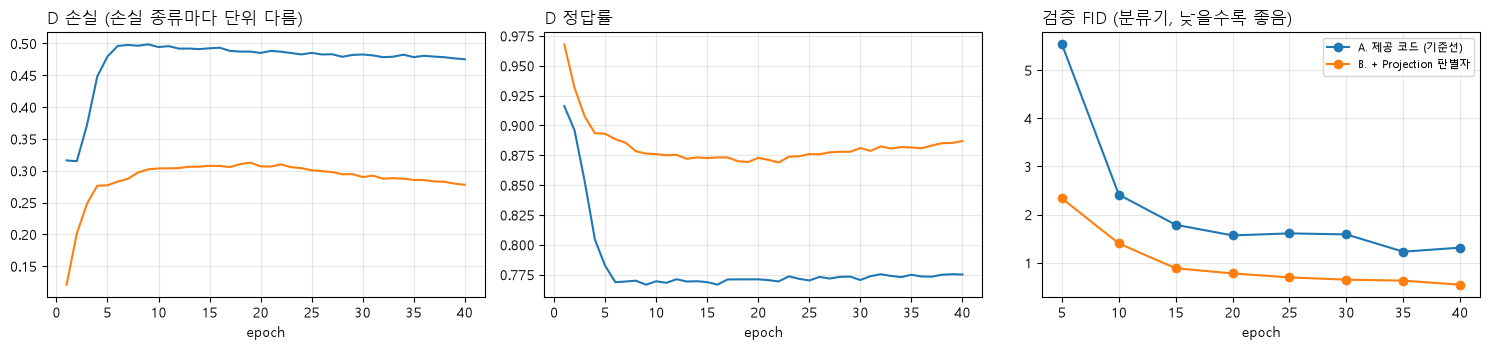

In [12]:
# 실험 1: 판별자가 클래스를 받는 방식 (나머지는 제공 코드 그대로)
CFG_A = dict(BASE)                                                     # 기준선 = 제공 코드
CFG_B = dict(BASE, D="Projection", loss="BCE")  # 판별자만 Projection (같은 BCE를 점수로 계산)
run("A. 제공 코드 (기준선)", CFG_A)                                    # 기준선 학습
run("B. + Projection 판별자", CFG_B)                                   # 조건 방식만 변경
display(compare(["A. 제공 코드 (기준선)", "B. + Projection 판별자"]))  # 검증 지표 비교
plot_curves(["A. 제공 코드 (기준선)", "B. + Projection 판별자"])       # 학습 곡선

**결과 해설**

```
A. 제공 코드        검증 FID(분류기) 1.230 · FID(Inception) 26.34 · precision 0.719 · recall 0.359
B. + Projection D   검증 FID(분류기) 0.544 · FID(Inception) 19.25 · precision 0.783 · recall 0.489
변화                 FID(분류기) -56% · recall +0.130 · 학습 시간 3.9분으로 같음
```

- 판별자의 조건 방식 하나만 바꿨는데 6개 지표 중 FID 2종 · 조건 일치율 · IS · precision · recall이 **모두** 좋아짐 → 이후 실험의 기준
- 학습 곡선 가운데: B의 판별자 정답률(약 0.88)이 A(약 0.77)보다 높음. 판별자가 더 정확한데 생성자도 더 좋아짐 → 판별자가 '클래스다움'까지 구체적으로 채점해 생성자에게 더 쓸모 있는 기울기를 줌
- 오른쪽 곡선: A는 35 epoch 이후 다시 올라가고, B는 40 epoch까지 계속 내려감

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| dict(기존, 키=값) | Python 내장 함수 | 한 항목만 바꾼 새 설정 | `dict(BASE, D="Projection", loss="BCE")` |
| run() · compare() · plot_curves() | 사용자 정의 함수 | 학습 · 비교표 · 곡선 | `run("B. + Projection 판별자", CFG_B)` |

### 4-5. 실험 2 · Spectral Norm

**한글 요약**

B에서 판별자의 **정규화 방식만** BatchNorm → Spectral Norm으로 바꿔 비교 (손실은 BCE 유지).

**실행 흐름**

1. **입력**: `CFG_B`
2. **처리**: C 학습 → B와 비교
3. **저장**: `RESULTS`의 C, `CFG_C`
4. **출력**: 검증 결과 · 학습 곡선

C. + Spectral Norm             검증 FID(분류기)   0.880 · FID(Inception)  22.30 · 조건 일치율 0.9303 (최고 40/40 epoch) · 6.9분


,FID (Inception),FID (분류기),IS (분류기),조건 일치율,precision,recall,최고 epoch
B. + Projection 판별자,19.2485,0.5439,8.5499,0.9292,0.7830,0.4892,40.0
C. + Spectral Norm,22.2973,0.8797,8.4019,0.9303,0.7547,0.4547,40.0


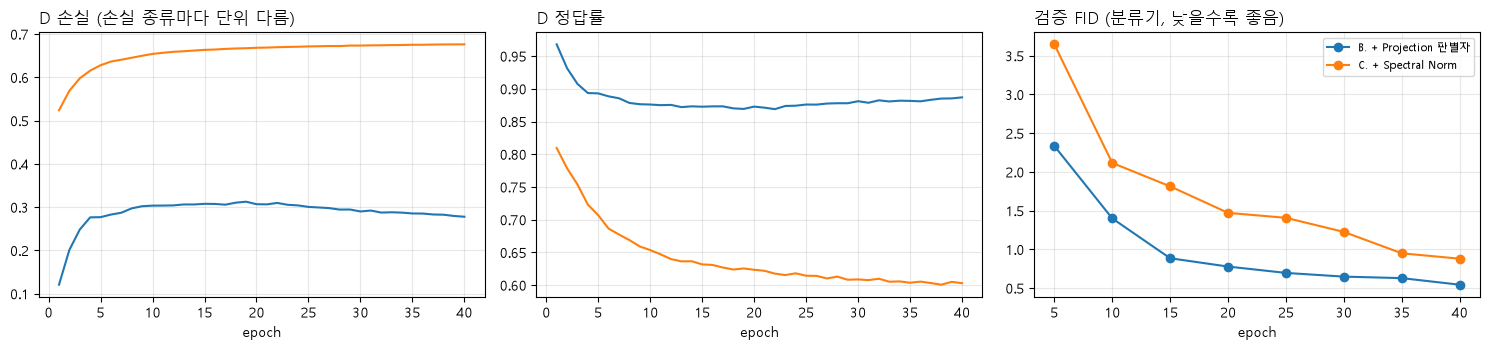

In [13]:
# 실험 2: 판별자 안정화 (BatchNorm → Spectral Norm), 손실은 BCE 유지
CFG_C = dict(CFG_B, D="Projection + SN")                            # 정규화 방식만 변경
run("C. + Spectral Norm", CFG_C)                                    # 학습
display(compare(["B. + Projection 판별자", "C. + Spectral Norm"]))  # 검증 지표 비교
plot_curves(["B. + Projection 판별자", "C. + Spectral Norm"])       # 학습 곡선

**결과 해설**

```
B. Projection D   검증 FID(분류기) 0.544 · recall 0.489
C. + SN           검증 FID(분류기) 0.880 · recall 0.455 · 학습 시간 3.9 → 6.9분
```

SN은 GAN 안정화의 표준 기법이지만 이 설정에서는 **나빠짐**. 가운데 곡선에서 C의 판별자 정답률이 약 0.60까지 떨어짐 → 층마다 기울기를 1로 묶자 작은 판별자가 진짜 · 가짜를 거의 못 가르게 되어, 생성자에게 주는 신호가 약해진 것으로 해석. 오른쪽 곡선은 40 epoch까지 내려가는 중이라 더 길게 학습하면 차이가 줄 수 있음. 기준은 B 유지.

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| dict(기존, 키=값) | Python 내장 함수 | 정규화 방식만 변경 | `dict(CFG_B, D="Projection + SN")` |
| run() · compare() · plot_curves() | 사용자 정의 함수 | 학습 · 비교표 · 곡선 | `run("C. + Spectral Norm", CFG_C)` |

### 4-6. 실험 3 · Hinge 손실

**한글 요약**

C에서 **손실만** BCE → Hinge로 바꿔 비교.

**실행 흐름**

1. **입력**: `CFG_C`
2. **처리**: D 학습 → C와 비교
3. **저장**: `RESULTS`의 D, `CFG_D`
4. **출력**: 검증 결과 · 학습 곡선

D. + Hinge 손실                  검증 FID(분류기)   0.928 · FID(Inception)  23.21 · 조건 일치율 0.9287 (최고 35/40 epoch) · 7.1분


,FID (Inception),FID (분류기),IS (분류기),조건 일치율,precision,recall,최고 epoch
C. + Spectral Norm,22.2973,0.8797,8.4019,0.9303,0.7547,0.4547,40.0
D. + Hinge 손실,23.2053,0.9284,8.3816,0.9287,0.7258,0.4530,35.0


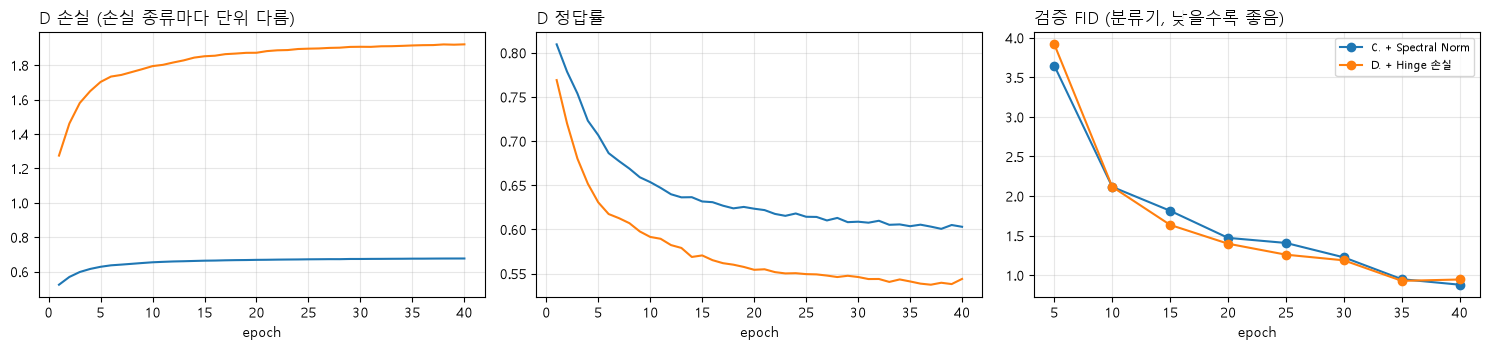

In [14]:
# 실험 3: 손실 함수 (BCE → Hinge)
CFG_D = dict(CFG_C, loss="Hinge")                            # 손실만 변경
run("D. + Hinge 손실", CFG_D)                                # 학습
display(compare(["C. + Spectral Norm", "D. + Hinge 손실"]))  # 검증 지표 비교
plot_curves(["C. + Spectral Norm", "D. + Hinge 손실"])       # 학습 곡선

**결과 해설**

```
C. + SN      검증 FID(분류기) 0.880 · precision 0.755
D. + Hinge   검증 FID(분류기) 0.928 · precision 0.726
```

Hinge는 SN과 함께 쓰는 조합으로 알려져 있어 C 위에서 비교. 판별자 정답률이 더 떨어지고(곡선 가운데, 약 0.54) 검증 FID도 0.05 나빠짐 → 판별자를 '덜 확신하게' 만드는 두 기법을 겹치니 이 작은 판별자에는 과함. A ~ D 중 1위는 여전히 B.

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| dict(기존, 키=값) | Python 내장 함수 | 손실만 변경 | `dict(CFG_C, loss="Hinge")` |
| run() · compare() · plot_curves() | 사용자 정의 함수 | 학습 · 비교표 · 곡선 | `run("D. + Hinge 손실", CFG_D)` |

### 4-7. 실험 4 · 옵티마이저 설정

**한글 요약**

- A ~ D 중 검증 FID(분류기) 1위 설정에서 **Adam 설정만** 변경
- **E1**: betas (0.5, 0.999) → (0.0, 0.9) · 과거 기울기 관성을 줄여 상대 모델 변화에 빨리 반응
- **E2**: TTUR · 생성자 1e-4 · 판별자 4e-4로 판별자를 더 빠르게 학습

**실행 흐름**

1. **입력**: `RESULTS`의 A ~ D
2. **처리**: 1위 설정 선택 → E1 · E2 학습 → 비교
3. **저장**: `RESULTS`의 E1 · E2, `STEP_NAMES` · `best_so_far` · `CFG_BEST`
4. **출력**: 기준 설정 이름 · 검증 결과 · 학습 곡선

실험 4의 기준: B. + Projection 판별자


E1. betas (0.0, 0.9)           검증 FID(분류기)   0.840 · FID(Inception)  20.77 · 조건 일치율 0.9258 (최고 35/40 epoch) · 4.4분


E2. TTUR (G 1e-4 · D 4e-4)     검증 FID(분류기)   0.980 · FID(Inception)  21.28 · 조건 일치율 0.9325 (최고 40/40 epoch) · 4.0분


,FID (Inception),FID (분류기),IS (분류기),조건 일치율,precision,recall,최고 epoch
B. + Projection 판별자,19.2485,0.5439,8.5499,0.9292,0.7830,0.4892,40.0
"E1. betas (0.0, 0.9)",20.7652,0.8401,8.3772,0.9258,0.7558,0.4768,35.0
E2. TTUR (G 1e-4 · D 4e-4),21.2794,0.9804,8.4969,0.9325,0.7697,0.4398,40.0


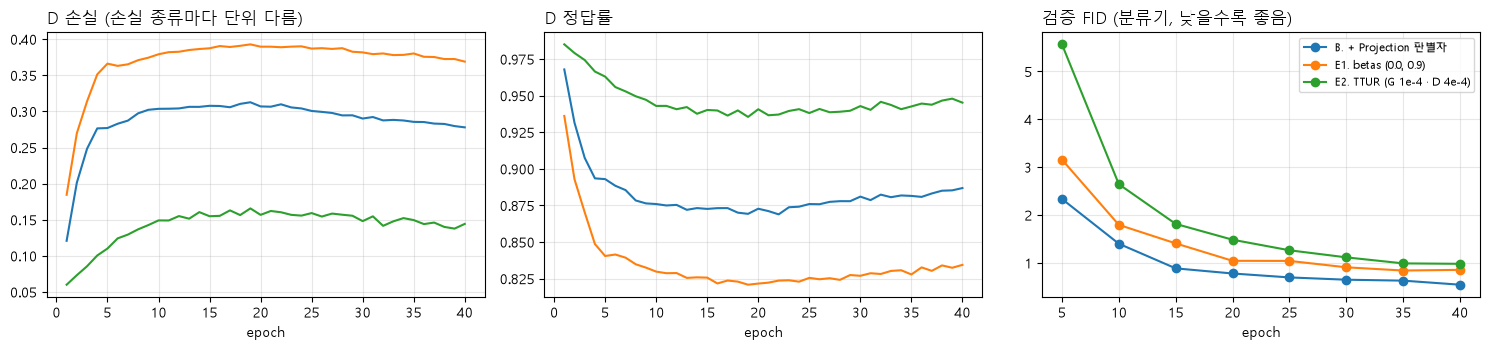

In [15]:
# 실험 4: 옵티마이저 설정 (지금까지 1위 설정에서 학습률 · betas만 변경)
# 지금까지 실험
STEP_NAMES = ["A. 제공 코드 (기준선)", "B. + Projection 판별자", "C. + Spectral Norm", "D. + Hinge 손실"]
best_so_far = min(STEP_NAMES, key=lambda n: RESULTS[n]["val"]["FID (분류기)"])  # 검증 FID 1위
CFG_BEST = RESULTS[best_so_far]["cfg"]                                   # 그 설정을 기준으로
print("실험 4의 기준:", best_so_far)                                     # 어느 설정에서 출발하는지
run("E1. betas (0.0, 0.9)", dict(CFG_BEST, betas=(0.0, 0.9)))            # 관성을 줄여 빠르게 반응
run("E2. TTUR (G 1e-4 · D 4e-4)", dict(CFG_BEST, lr_G=1e-4, lr_D=4e-4))  # 판별자를 더 빠르게
# 검증 지표 비교
display(compare([best_so_far, "E1. betas (0.0, 0.9)", "E2. TTUR (G 1e-4 · D 4e-4)"]))
plot_curves([best_so_far, "E1. betas (0.0, 0.9)", "E2. TTUR (G 1e-4 · D 4e-4)"])  # 학습 곡선

**결과 해설**

```
실험 4 기준       B. Projection D (A ~ D 중 검증 1위)
E1. betas (0, 0.9)  검증 FID(분류기) 0.840 · 판별자 정답률 약 0.83
E2. TTUR            검증 FID(분류기) 0.980 · 판별자 정답률 약 0.94
B (기준)            검증 FID(분류기) 0.544 · 판별자 정답률 약 0.88
```

두 설정 모두 B보다 나쁨. E2는 판별자 학습률을 4배로 올리자 판별자가 너무 강해지고(정답률 0.94), E1은 관성을 없애자 판별자가 약해짐(0.83). 곡선을 보면 기준 B의 판별자 정답률이 두 설정의 **가운데**에 있음 → 제공 코드의 Adam 설정(2e-4, betas 0.5 · 0.999)이 이 모델 크기에서는 이미 균형점. 기준은 B 유지.

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| min(key=) | Python 내장 함수 | 검증 FID 1위 실험 이름 | `min(STEP_NAMES, key=lambda n: RESULTS[n]["val"]["FID (분류기)"])` |
| dict(기존, 키=값) | Python 내장 함수 | Adam 설정만 변경 | `dict(CFG_BEST, lr_G=1e-4, lr_D=4e-4)` |
| run() · compare() · plot_curves() | 사용자 정의 함수 | 학습 · 비교표 · 곡선 | `run("E1. betas (0.0, 0.9)", ...)` |

### 4-8. 실험 5 · 데이터 증강

**한글 요약**

- 지금까지 1위 설정에서 **증강만** 변경
- **F1 좌우 반전**: 흔히 쓰는 증강, 1-3에서 신발의 방향이 한쪽으로 쏠린 것을 확인 → 생성 분포가 바뀌는지 직접 측정
- **F2 이동 ±2px**: 판별자 입력의 진짜 · 가짜를 모두 같은 방식으로 옮김 → 판별자 과적합만 줄이고 생성 이미지는 옮겨지지 않음

**실행 흐름**

1. **입력**: `RESULTS` · `shape_table`
2. **처리**: 1위 설정 선택 → F1 · F2 학습 → 검증 비교 → 신발 3종의 '왼쪽이 더 무거운 비율'을 생성 이미지에서 계산
3. **저장**: `RESULTS`의 F1 · F2
4. **출력**: 검증 결과 · 신발 방향 비교표

In [16]:
# 실험 5: 데이터 증강 (지금까지 1위 설정에서 증강만 변경)
STEP_NAMES += ["E1. betas (0.0, 0.9)", "E2. TTUR (G 1e-4 · D 4e-4)"]  # 비교 후보 추가
best_so_far = min(STEP_NAMES, key=lambda n: RESULTS[n]["val"]["FID (분류기)"])  # 검증 FID 1위
CFG_BEST = RESULTS[best_so_far]["cfg"]                                # 증강 실험의 기준
print("실험 5의 기준:", best_so_far)                                  # 어느 설정에서 출발하는지
run("F1. 좌우 반전 (진짜 이미지)", dict(CFG_BEST, aug="좌우 반전"))   # 일반적인 이미지 증강
run("F2. 이동 ±2px (D 입력 전체)", dict(CFG_BEST, aug="이동"))        # 진짜 · 가짜 모두 같은 증강
# 검증 지표 비교
display(compare([best_so_far, "F1. 좌우 반전 (진짜 이미지)", "F2. 이동 ±2px (D 입력 전체)"]))

# 신발 방향 확인 (1-3의 왼쪽 밝기 비율을 생성 이미지에서 다시 계산)
rows = {}                                                  # 실험별 신발 클래스의 왼쪽이 무거운 비율
for n in [best_so_far, "F1. 좌우 반전 (진짜 이미지)"]:     # 기준 · 반전 실험
    imgs = (generate(RESULTS[n]["G"].to(device), VAL_Z, VAL_Y)[:, 0] + 1) / 2  # [0, 1] 이미지
    left = imgs[:, :, :14].sum((1, 2)) / imgs.sum((1, 2))  # 왼쪽 절반 밝기 비율
    # 신발 3종
    rows[n] = {CLASSES[c]: (left[VAL_Y == c] > 0.5).float().mean().item() for c in (5, 7, 9)}
# 1-3의 실제 값
rows["실제 학습 이미지"] = shape_table.loc[[CLASSES[c] for c in (5, 7, 9)], "왼쪽이 더 무거운 비율"].to_dict()
display(pd.DataFrame(rows).T.round(3))                     # 0.5에 가까울수록 방향이 섞임

실험 5의 기준: B. + Projection 판별자


F1. 좌우 반전 (진짜 이미지)             검증 FID(분류기)   2.546 · FID(Inception)  23.74 · 조건 일치율 0.8218 (최고 40/40 epoch) · 3.9분


F2. 이동 ±2px (D 입력 전체)          검증 FID(분류기)   0.720 · FID(Inception)  19.77 · 조건 일치율 0.9320 (최고 40/40 epoch) · 4.5분


,FID (Inception),FID (분류기),IS (분류기),조건 일치율,precision,recall,최고 epoch
B. + Projection 판별자,19.2485,0.5439,8.5499,0.9292,0.7830,0.4892,40.0
F1. 좌우 반전 (진짜 이미지),23.7394,2.5460,7.4550,0.8218,0.7443,0.4675,40.0
F2. 이동 ±2px (D 입력 전체),19.7740,0.7204,8.6626,0.9320,0.8113,0.3717,40.0


,Sandal,Sneaker,Ankle boot
B. + Projection 판별자,0.075,0.003,0.000
F1. 좌우 반전 (진짜 이미지),0.382,0.515,0.463
실제 학습 이미지,0.081,0.006,0.000


**결과 해설**

```
F1. 좌우 반전   검증 FID(분류기) 2.546 · 조건 일치율 0.822 : 전체 실험 중 최하위
F2. 이동 ±2px   검증 FID(분류기) 0.720 · precision 0.811 · recall 0.372 : 사실성 ↑ · 다양성 ↓
'왼쪽이 더 무거운 비율'  실제 Sandal 0.081 · Sneaker 0.006 · Ankle boot 0.000
                         B      0.075 · 0.003 · 0.000  : 실제와 같은 방향
                         F1     0.382 · 0.515 · 0.463  : 신발 절반이 뒤집힌 방향으로 생성
```

- **1-3의 예상이 수치로 확인됨**: 반전 증강을 쓰자 생성자가 데이터에 없는 '오른쪽을 보는 신발'을 절반가량 만듦. 판정 분류기는 원래 방향만 보고 배웠으므로 일치율이 0.93 → 0.82로 떨어지고 FID도 4.7배 나빠짐
- **IS만 보면 놓침**: F1의 IS 7.46은 B 8.55보다 낮지만 FID(Inception) 23.7은 C · D와 비슷한 수준 → 방향 오류는 분류기 기반 지표에서 훨씬 크게 드러남
- **F2는 교환 관계**: precision은 전체 1위(0.811)지만 recall이 0.489 → 0.372로 떨어져, 판별자가 위치 차이를 무시하게 되자 생성자가 '안전한 모양'에 몰림. 검증 FID 기준으로 채택하지 않음

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| min(key=) · dict(기존, 키=값) | Python 내장 함수 | 기준 설정 · 증강만 변경 | `dict(CFG_BEST, aug="좌우 반전")` |
| sum((1, 2)) · float().mean() | torch | 왼쪽 절반 밝기 · 비율 | `imgs[:, :, :14].sum((1, 2)) / imgs.sum((1, 2))` |
| loc[] · to_dict() | pandas | 신발 3종 행 선택 · 사전 변환 | `shape_table.loc[[...], "왼쪽이 더 무거운 비율"].to_dict()` |
| += (리스트) | Python 기본 문법 | 비교 후보 추가 | `STEP_NAMES += [...]` |

### 4-9. 실험 6 · 생성자 구조

**한글 요약**

지금까지 1위 설정에서 **생성자만** 넓은 생성자로 바꿔 비교. 마지막에 전체 실험을 검증 FID(분류기) 순으로 정리.

**실행 흐름**

1. **입력**: `RESULTS` · `WideGenerator`
2. **처리**: 1위 설정 선택 → G 학습 → 비교 → 전체 요약표
3. **저장**: `RESULTS`의 G, `summary`
4. **출력**: 검증 결과 · 학습 곡선 · 전체 실험 표

실험 6의 기준: B. + Projection 판별자


G. + 넓은 생성자                    검증 FID(분류기)   0.603 · FID(Inception)  18.70 · 조건 일치율 0.9338 (최고 40/40 epoch) · 8.0분


,FID (Inception),FID (분류기),IS (분류기),조건 일치율,precision,recall,최고 epoch
B. + Projection 판별자,19.2485,0.5439,8.5499,0.9292,0.7830,0.4892,40.0
G. + 넓은 생성자,18.6983,0.6029,8.6003,0.9338,0.7857,0.4893,40.0


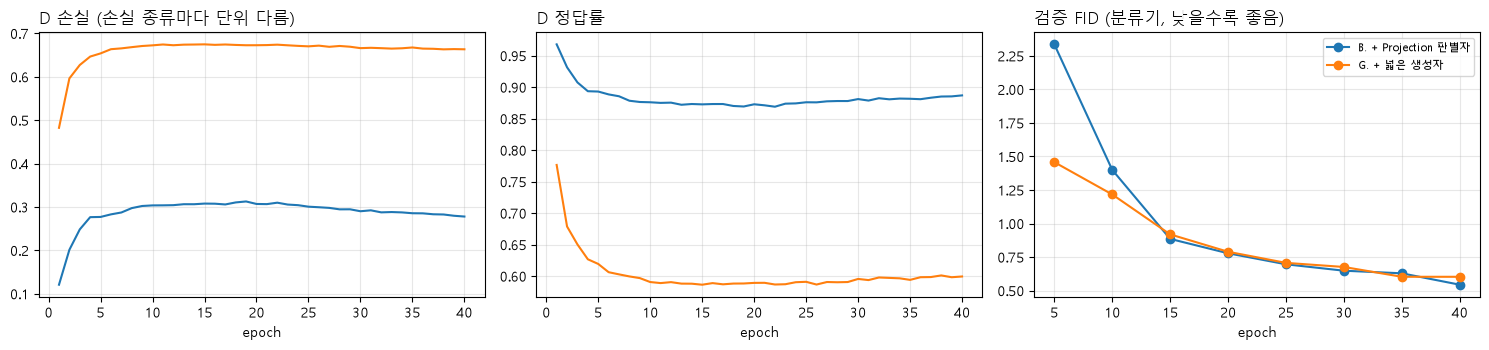

,FID (Inception),FID (분류기),IS (분류기),조건 일치율,precision,recall,최고 epoch,학습 시간(분)
B. + Projection 판별자,19.2485,0.5439,8.5499,0.9292,0.7830,0.4892,40.0,3.9
G. + 넓은 생성자,18.6983,0.6029,8.6003,0.9338,0.7857,0.4893,40.0,8.0
F2. 이동 ±2px (D 입력 전체),19.7740,0.7204,8.6626,0.9320,0.8113,0.3717,40.0,4.5
"E1. betas (0.0, 0.9)",20.7652,0.8401,8.3772,0.9258,0.7558,0.4768,35.0,4.4
C. + Spectral Norm,22.2973,0.8797,8.4019,0.9303,0.7547,0.4547,40.0,6.9
D. + Hinge 손실,23.2053,0.9284,8.3816,0.9287,0.7258,0.4530,35.0,7.1
E2. TTUR (G 1e-4 · D 4e-4),21.2794,0.9804,8.4969,0.9325,0.7697,0.4398,40.0,4.0
A. 제공 코드 (기준선),26.3407,1.2299,8.2227,0.9247,0.7188,0.3593,35.0,3.9
F1. 좌우 반전 (진짜 이미지),23.7394,2.5460,7.4550,0.8218,0.7443,0.4675,40.0,3.9


In [17]:
# 실험 6: 생성자 구조 (지금까지 1위 설정에서 생성자만 변경)
STEP_NAMES += ["F1. 좌우 반전 (진짜 이미지)", "F2. 이동 ±2px (D 입력 전체)"]  # 비교 후보 추가
best_so_far = min(STEP_NAMES, key=lambda n: RESULTS[n]["val"]["FID (분류기)"])  # 검증 FID 1위
CFG_BEST = RESULTS[best_so_far]["cfg"]               # 구조 실험의 기준
print("실험 6의 기준:", best_so_far)                 # 어느 설정에서 출발하는지
run("G. + 넓은 생성자", dict(CFG_BEST, G="넓은 G"))  # 채널 2배 · 합성곱 2층 추가
STEP_NAMES += ["G. + 넓은 생성자"]                   # 비교 후보 추가
display(compare([best_so_far, "G. + 넓은 생성자"]))  # 검증 지표 비교
plot_curves([best_so_far, "G. + 넓은 생성자"])       # 학습 곡선

# 지금까지의 전체 비교
summary = compare(STEP_NAMES)                 # 모든 실험의 검증 지표
summary["학습 시간(분)"] = [round(RESULTS[n]["minutes"], 1) for n in STEP_NAMES]  # 비용
display(summary.sort_values("FID (분류기)"))  # 검증 FID 순

**결과 해설**

```
G. + 넓은 생성자  검증 FID(분류기) 0.603 · FID(Inception) 18.70 · 조건 일치율 0.9338 · recall 0.489
B (기준)          검증 FID(분류기) 0.544 · FID(Inception) 19.25 · 조건 일치율 0.9292 · recall 0.489
전체 9개 실험 순위 B 0.544 → G 0.603 → F2 0.720 → E1 0.840 → … → A 1.230 → F1 2.546
```

G는 FID(Inception) · 조건 일치율 · IS · precision에서 B보다 좋고, FID(분류기)만 0.06 나쁨 → **seed 하나로는 우열을 가릴 수 없는 차이**. 곡선 오른쪽에서 15 epoch 이후 두 선이 거의 겹치고, 가운데에서 G의 판별자 정답률이 약 0.60으로 낮음(생성자가 강해져 판별자를 더 잘 속임). 학습 시간은 3.9 → 8.0분. 상위 2개(B · G)를 4-10에서 seed 반복으로 다시 비교.

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| sort_values() | pandas | 검증 FID 순 정렬 | `summary.sort_values("FID (분류기)")` |
| run() · compare() · plot_curves() | 사용자 정의 함수 | 학습 · 비교표 · 곡선 | `run("G. + 넓은 생성자", dict(CFG_BEST, G="넓은 G"))` |
| 리스트 컴프리헨션 | Python 기본 문법 | 실험별 학습 시간 | `[round(RESULTS[n]["minutes"], 1) for n in STEP_NAMES]` |

### 4-10. seed 반복과 최종 설정

**한글 요약**

- 한 번의 차이는 초기값 운일 수 있음 → 검증 FID 상위 2개 설정을 seed 1 · 2로 **두 번씩 더** 학습
- seed 3개의 **평균** 검증 FID(분류기)가 낮은 설정을 최종 설정으로, 그중 검증 1위 seed의 모델을 선택

**실행 흐름**

1. **입력**: `summary` · `RESULTS`
2. **처리**: 상위 2개 → seed 2개씩 추가 학습 → 설정별 평균 · 표준편차 → 최종 설정 · 실행 선택
3. **저장**: `seed_table` · `FINAL_SETTING` · `FINAL_KEY`
4. **출력**: seed별 결과 요약 · 최종 선택

In [18]:
# seed 반복: 검증 FID 상위 2개 설정을 seed 2개씩 더 학습
def seed_name(n, seed):                       # seed 반복 실험 이름
    return f"{n.split('.')[0]}. seed {seed}"  # 예: "D. seed 1"


top2 = summary.sort_values("FID (분류기)").index[:2].tolist()  # 후보 2개
print("후보:", top2)                                           # 반복할 설정
for seed in [1, 2]:                                            # 추가 seed
    for n in top2:                                             # 후보 설정
        run(seed_name(n, seed), RESULTS[n]["cfg"], seed=seed)  # 같은 설정 · 다른 seed

# 설정별 평균 · 표준편차 (seed 42 · 1 · 2)
rows = []                                              # 실행 하나당 한 행
for n in top2:                                         # 후보 설정
    for key in [n, seed_name(n, 1), seed_name(n, 2)]:  # seed 42 · 1 · 2 실행
        rows.append({"설정": n, "seed": RESULTS[key]["seed"], **RESULTS[key]["val"]})  # 지표 기록
seed_table = pd.DataFrame(rows)                        # 6행
# 평균 · 편차
display(seed_table.drop(columns="seed").groupby("설정").agg(["mean", "std"]).round(4).T)

# 최종 설정: 평균 검증 FID(분류기)가 낮은 설정, 그중 검증 1위 seed
FINAL_SETTING = seed_table.groupby("설정")["FID (분류기)"].mean().idxmin()  # 평균 1위 설정
# 그 설정에서 검증 1위 seed
best_seed = seed_table[seed_table["설정"] == FINAL_SETTING].sort_values("FID (분류기)").iloc[0]["seed"]
# 실행 이름
FINAL_KEY = FINAL_SETTING if best_seed == SEED else seed_name(FINAL_SETTING, int(best_seed))
print("최종 설정:", FINAL_SETTING, "| 선택된 실행:", FINAL_KEY)             # 선택 결과

후보: ['B. + Projection 판별자', 'G. + 넓은 생성자']


B. seed 1                      검증 FID(분류기)   0.778 · FID(Inception)  20.82 · 조건 일치율 0.9308 (최고 35/40 epoch) · 4.0분


G. seed 1                      검증 FID(분류기)   0.424 · FID(Inception)  18.61 · 조건 일치율 0.9418 (최고 35/40 epoch) · 8.1분


B. seed 2                      검증 FID(분류기)   0.515 · FID(Inception)  19.91 · 조건 일치율 0.9323 (최고 40/40 epoch) · 4.3분


G. seed 2                      검증 FID(분류기)   0.572 · FID(Inception)  21.09 · 조건 일치율 0.9327 (최고 15/40 epoch) · 7.8분


설정                    B. + Projection 판별자  G. + 넓은 생성자
FID (Inception) mean              19.9906      19.4659
                std                0.7880       1.4070
FID (분류기)       mean               0.6124       0.5330
                std                0.1439       0.0954
IS (분류기)        mean               8.5493       8.5894
                std                0.0478       0.0533
조건 일치율          mean               0.9308       0.9361
                std                0.0016       0.0050
precision       mean               0.7902       0.7860
                std                0.0111       0.0343
recall          mean               0.4606       0.4565
                std                0.0253       0.0288

최종 설정: G. + 넓은 생성자 | 선택된 실행: G. seed 1


**결과 해설**

```
B  seed 42 · 1 · 2   검증 FID(분류기) 0.544 · 0.778 · 0.515 → 평균 0.612 · 표준편차 0.144
G  seed 42 · 1 · 2   검증 FID(분류기) 0.603 · 0.424 · 0.572 → 평균 0.533 · 표준편차 0.095
평균 조건 일치율     B 0.9308 · G 0.9361
최종 설정 G · 선택된 실행 G seed 1 (검증 0.424)
```

seed 42 한 번만 보면 B가 1위였지만 **세 번 평균에서는 G가 0.08 낮고 흔들림(표준편차)도 작음** → 4-9의 순위는 seed 운이었음. 한 번의 비교로 설정을 고르면 안 되는 이유를 보여주는 결과. G seed 2는 15 epoch에서 최고를 찍은 뒤 나빠짐 → 넓은 생성자도 학습 후반에 흔들릴 수 있음 (4-11에서 학습량 확인).

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| index[:2] · tolist() | pandas | 상위 2개 설정 이름 | `summary.sort_values(...).index[:2].tolist()` |
| groupby().agg(["mean", "std"]) · idxmin()<br>drop(columns=) · iloc[] | pandas | 설정별 평균 · 편차 · 평균 1위<br>열 빼기 · 첫 행 | `seed_table.groupby("설정")["FID (분류기)"].mean().idxmin()`<br>`.sort_values("FID (분류기)").iloc[0]` |
| split() | Python 내장 메서드 | 실험 기호만 꺼내기 | `n.split('.')[0]` |
| seed_name() | 사용자 정의 함수 | seed 반복 실험 이름 | `seed_name(n, seed)` |
| 중첩 for · 조건 표현식 | Python 기본 문법 | 설정 × seed 반복 · 실행 이름 선택 | `for seed in [1, 2]:` · `FINAL_SETTING if ... else seed_name(...)` |

### 4-11. 에폭 수

**한글 요약**

- 미션의 하이퍼파라미터 항목 중 **에폭 수** 확인: 최종 설정을 같은 seed로 80 epoch까지 학습
- 5 epoch마다 잰 검증 곡선으로 40 epoch 이후에도 좋아지는지 보고, 40 · 80 epoch 중 검증 FID가 낮은 쪽을 최종 모델로

**실행 흐름**

1. **입력**: `FINAL_KEY`
2. **처리**: 80 epoch 학습 → epoch별 검증 지표 → 두 학습량 비교 → 최종 모델 선택
3. **저장**: `RESULTS`의 H, `FINAL_RUN`
4. **출력**: epoch별 검증 표 · 비교표 · 검증 곡선

H. 최종 설정 · 80 epoch            검증 FID(분류기)   0.328 · FID(Inception)  17.25 · 조건 일치율 0.9362 (최고 75/80 epoch) · 15.1분


epoch,5,10,15,20,25,30,35,40,45,50,55,60,65,70,75,80
검증 FID (분류기),2.0685,1.3675,0.7024,0.6729,1.3049,0.5365,0.4243,0.5771,0.3907,0.4067,0.3622,0.4088,0.4338,0.3997,0.3275,0.3656
검증 조건 일치율,0.9197,0.9218,0.9427,0.9348,0.9265,0.9473,0.9418,0.9407,0.9503,0.9325,0.9467,0.9422,0.9408,0.9445,0.9362,0.9432


,FID (Inception),FID (분류기),IS (분류기),조건 일치율,precision,recall,최고 epoch
G. seed 1,18.6097,0.4243,8.6364,0.9418,0.8205,0.4357,35.0
H. 최종 설정 · 80 epoch,17.2467,0.3275,8.6435,0.9362,0.8188,0.5020,75.0


최종 모델: H. 최종 설정 · 80 epoch


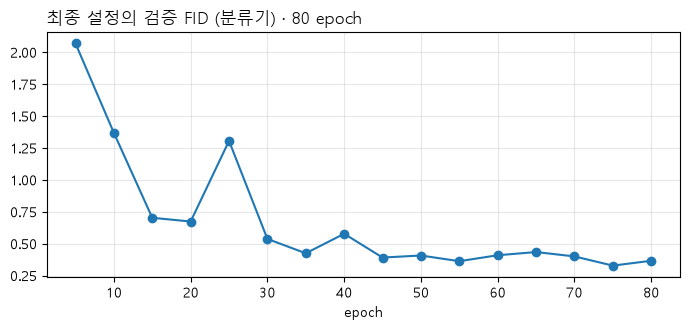

In [19]:
# 에폭 수: 최종 설정을 80 epoch까지 학습해 검증 곡선 확인
cfg_long = dict(RESULTS[FINAL_KEY]["cfg"], epochs=80)                      # 학습량만 2배
run("H. 최종 설정 · 80 epoch", cfg_long, seed=RESULTS[FINAL_KEY]["seed"])  # 같은 seed
# 검증한 epoch만
h = RESULTS["H. 최종 설정 · 80 epoch"]["history"].dropna(subset=["검증 FID (분류기)"])
# epoch별 검증 지표
display(h.set_index("epoch")[["검증 FID (분류기)", "검증 조건 일치율"]].T.round(4))

# 40 epoch vs 80 epoch 중 검증 FID가 낮은 쪽을 최종 모델로
# 검증 FID가 낮은 학습량
FINAL_RUN = min([FINAL_KEY, "H. 최종 설정 · 80 epoch"], key=lambda n: RESULTS[n]["val"]["FID (분류기)"])
display(compare([FINAL_KEY, "H. 최종 설정 · 80 epoch"]))  # 두 학습량 비교
print("최종 모델:", FINAL_RUN)                            # 시험 평가에 쓸 모델

# 검증 곡선
fig, ax = plt.subplots(figsize=(7, 3.4))                              # 한 그래프
ax.plot(h["epoch"], h["검증 FID (분류기)"], marker="o")               # epoch별 검증 FID
ax.set_title("최종 설정의 검증 FID (분류기) · 80 epoch", loc="left")  # 그래프 제목
ax.set_xlabel("epoch")                                                # 가로축
ax.grid(alpha=0.3)                                                    # 옅은 격자
plt.tight_layout()                                                    # 간격 정리
plt.show()                                                            # 그래프 출력

**결과 해설**

```
G seed 1 · 40 epoch   검증 FID(분류기) 0.424 (35 epoch) · recall 0.436
H. 같은 seed · 80 epoch 검증 FID(분류기) 0.328 (75 epoch) · recall 0.502 · FID(Inception) 17.25
epoch 35 값 0.4243     : 40 epoch 실행과 소수 넷째 자리까지 같음 (같은 seed → 같은 경로)
25 epoch 1.305         : 학습 중간에 일시적으로 크게 나빠졌다 회복
```

- 40 epoch 이후에도 검증 FID가 0.36 ~ 0.43 사이를 오가며 75 epoch 0.33까지 천천히 내려감 → 80 epoch(H)를 최종 모델로 선택
- recall이 0.436 → 0.502로 가장 크게 오름: 학습을 길게 하면 '더 다양한 모양'을 덮게 됨
- 곡선의 25 epoch 튐처럼 GAN은 중간에 흔들리므로, 마지막 epoch가 아니라 **5 epoch마다 검증해 최고 시점을 복원**하는 방식이 필요

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| dict(기존, epochs=80) | Python 내장 함수 | 학습량만 2배 | `dict(RESULTS[FINAL_KEY]["cfg"], epochs=80)` |
| set_index() · T | pandas | epoch별 검증 지표를 가로로 | `h.set_index("epoch")[[...]].T` |
| plot(marker=) · grid() | matplotlib | 검증 곡선 · 격자 | `ax.plot(h["epoch"], h["검증 FID (분류기)"], marker="o")` |
| min(key=) | Python 내장 함수 | 두 학습량 중 검증 1위 | `min([FINAL_KEY, "H. ..."], key=...)` |

---
## 5. test 평가

### 5-1. test 정량 평가

**한글 요약**

- 검증으로 고른 최종 모델과 기준선 A를 **같은 잡음 · 같은 클래스**(클래스당 1,000장)로 생성해 test 10,000장과 한 번 비교
- 실제 학습 이미지 10,000장의 값을 바닥 기준선으로 함께 표시

**실행 흐름**

1. **입력**: `RESULTS` · `TEST_Z` · `TEST_Y` · `REF_TEST`
2. **처리**: 두 생성자로 10,000장씩 생성 → 6개 지표 → 기준선 대비 변화
3. **저장**: `FAKE_BASE` · `FAKE_FINAL` · `G_final` · `test_table`
4. **출력**: test 지표 표 · 변화량

In [20]:
# 시험 10,000장 기준 최종 평가 (기준선 · 최종 모델, 한 번만)
G_base = RESULTS["A. 제공 코드 (기준선)"]["G"].to(device)  # 기준선 생성자
G_final = RESULTS[FINAL_RUN]["G"].to(device)               # 최종 생성자
FAKE_BASE = generate(G_base, TEST_Z, TEST_Y)               # 같은 잡음 · 같은 클래스로 10,000장
FAKE_FINAL = generate(G_final, TEST_Z, TEST_Y)             # 클래스마다 1,000장
# 바닥 기준선 · 기준선 · 최종
TEST_ROWS = {"실제 학습 10,000 (바닥 기준선)": REAL_ROWS["실제 학습 10,000 vs 시험"],
             "A. 제공 코드 (기준선)": evaluate(FAKE_BASE, TEST_Y, REF_TEST),
             f"최종 ({FINAL_RUN})": evaluate(FAKE_FINAL, TEST_Y, REF_TEST)}
test_table = pd.DataFrame(TEST_ROWS).T                     # 3행
display(test_table.round(4))                               # 시험 지표

# 기준선 대비 변화
b, f_ = test_table.iloc[1], test_table.iloc[2]                          # 기준선 · 최종
for k in ["FID (Inception)", "FID (분류기)"]:                           # 낮을수록 좋은 지표
    print(f"{k:<16} {b[k]:8.3f} → {f_[k]:8.3f} ({(f_[k] - b[k]) / b[k]:+.1%})")  # 낮을수록 좋음
for k in ["IS (분류기)", "조건 일치율", "precision", "recall"]:         # 높을수록 좋은 지표
    print(f"{k:<16} {b[k]:8.4f} → {f_[k]:8.4f} ({f_[k] - b[k]:+.4f})")  # 높을수록 좋음

,FID (Inception),FID (분류기),IS (분류기),조건 일치율,precision,recall
"실제 학습 10,000 (바닥 기준선)",2.7298,0.0295,9.1012,0.9879,0.8608,0.8620
A. 제공 코드 (기준선),25.0124,1.2296,8.2511,0.9235,0.7112,0.3107
최종 (H. 최종 설정 · 80 epoch),15.5290,0.3424,8.6103,0.9400,0.7977,0.4779


FID (Inception)    25.012 →   15.529 (-37.9%)
FID (분류기)           1.230 →    0.342 (-72.2%)
IS (분류기)           8.2511 →   8.6103 (+0.3592)
조건 일치율             0.9235 →   0.9400 (+0.0165)
precision          0.7112 →   0.7977 (+0.0865)
recall             0.3107 →   0.4779 (+0.1672)


**결과 해설**

```
                         FID(Inception)  FID(분류기)  IS     조건 일치율  precision  recall
실제 학습 10,000 (바닥)       2.73          0.030     9.10    0.988       0.861     0.862
A. 제공 코드                 25.01          1.230     8.25    0.924       0.711     0.311
최종 (H)                     15.53          0.342     8.61    0.940       0.798     0.478
변화                        -37.9%        -72.2%    +0.36   +0.017      +0.087    +0.167
```

- **6개 지표 모두 개선**, test에서도 검증과 같은 방향 → 검증으로 고른 결과가 처음 보는 10,000장에서도 유지됨
- **가장 큰 개선은 recall**(0.311 → 0.478): 제공 코드는 진짜 이미지의 다양한 모양 중 31%만 덮었고, 최종 모델은 48%
- **남은 거리**: recall은 바닥 기준선 0.862와 아직 0.38 차이 → 생성 품질보다 **다양성**이 남은 과제. 조건 일치율 0.940은 판정 도구의 실제 test 정확도(0.928)보다도 높음 → 생성 이미지가 실제보다 '전형적인' 모양에 몰려 있다는 신호와 일치

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| generate() · evaluate() | 사용자 정의 함수 | 같은 잡음으로 생성 · test 지표 | `generate(G_final, TEST_Z, TEST_Y)` · `evaluate(FAKE_FINAL, TEST_Y, REF_TEST)` |
| DataFrame().T · iloc[] | pandas | test 지표 표 · 행 선택 | `pd.DataFrame(TEST_ROWS).T` · `test_table.iloc[1]` |
| f-string 형식 `:+.1%` · `:+.4f` | Python 기본 문법 | 부호 있는 변화율 · 변화량 | `f"({(f_[k] - b[k]) / b[k]:+.1%})"` |

### 5-2. 클래스별 조건 일치

**한글 요약**

- 클래스마다 조건 일치율과 FID(분류기)를 기준선 · 최종 모델로 비교
- 판정 도구의 실제 test recall을 옆에 두어, 낮은 일치율이 **생성 문제**인지 **판정 도구 한계**인지 구분
- 최종 모델 생성 이미지가 어떤 클래스로 잘못 판정되는지 혼동 행렬로 확인

**실행 흐름**

1. **입력**: `FAKE_BASE` · `FAKE_FINAL` · `REF_TEST` · `real_recall`
2. **처리**: 특징 · 확률 → 클래스별 일치율 · FID → 요청 × 판정 혼동 행렬
3. **저장**: `f_base` · `f_final` · `f_test` · `per_class`
4. **출력**: 클래스별 표 · 혼동 행렬

,실제 test recall,기준선 일치율,최종 일치율,기준선 FID(분류기),최종 FID(분류기)
T-shirt/top,0.879,0.937,0.914,2.834,0.924
Trouser,0.985,1.000,0.988,0.694,0.547
Pullover,0.896,0.810,0.899,2.664,0.882
Dress,0.925,0.960,0.958,1.520,0.583
Coat,0.898,0.799,0.907,2.988,0.803
Sandal,0.985,0.996,0.991,1.547,0.501
Shirt,0.778,0.823,0.839,4.469,0.985
Sneaker,0.979,0.946,0.926,1.421,1.364
Bag,0.990,0.987,0.994,2.693,0.877
Ankle boot,0.969,0.977,0.984,0.919,0.508


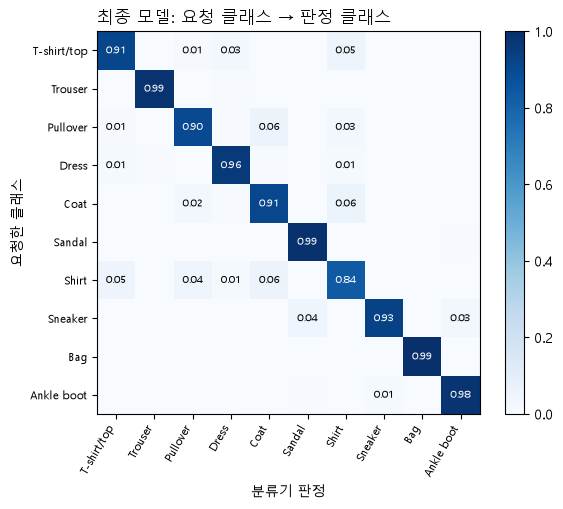

In [21]:
# 클래스별 조건 일치율 vs 실제 이미지 판정 정확도
f_base, p_base = clf_out(FAKE_BASE)          # 기준선 특징 · 확률
f_final, p_final = clf_out(FAKE_FINAL)       # 최종 특징 · 확률
f_test = REF_TEST["clf"]                     # 시험 이미지 특징
per_class = pd.DataFrame({                   # 클래스별 비교표
    "실제 test recall": real_recall.values,  # 판정 도구 자체의 정확도 (상한 참고)
    "기준선 일치율": [(p_base.argmax(1)[TEST_Y.numpy() == c] == c).mean() for c in range(10)],
    "최종 일치율": [(p_final.argmax(1)[TEST_Y.numpy() == c] == c).mean() for c in range(10)],
    "기준선 FID(분류기)": [fid(f_base[TEST_Y.numpy() == c], f_test[y_te.numpy() == c]) for c in range(10)],
    "최종 FID(분류기)": [fid(f_final[TEST_Y.numpy() == c], f_test[y_te.numpy() == c]) for c in range(10)],
}, index=CLASSES)                            # 클래스마다 1,000장끼리
display(per_class.round(3))                  # 클래스별 표

# 최종 모델 생성 이미지의 판정 혼동 행렬 (행 = 요청한 클래스)
cm = np.zeros((10, 10))                                                             # 요청 × 판정
np.add.at(cm, (TEST_Y.numpy(), p_final.argmax(1)), 1)                               # 칸마다 개수
cm = cm / cm.sum(1, keepdims=True)                                                  # 행 비율
fig, ax = plt.subplots(figsize=(6.2, 5.2))                                          # 정사각 히트맵
im = ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)                                    # 진할수록 많음
for i in range(10):                                                                 # 행
    for j in range(10):                                                             # 열
        if cm[i, j] >= 0.01:                                                        # 1% 이상 칸만
            ax.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center", fontsize=7,  # 칸 숫자
                    color="white" if cm[i, j] > 0.6 else "black")                   # 1% 이상만 표시
ax.set_xticks(range(10), CLASSES, rotation=60, ha="right", fontsize=8)              # 판정 클래스
ax.set_yticks(range(10), CLASSES, fontsize=8)                                       # 요청 클래스
ax.set_xlabel("분류기 판정")                                                        # 가로축
ax.set_ylabel("요청한 클래스")                                                      # 세로축
ax.set_title("최종 모델: 요청 클래스 → 판정 클래스", loc="left")                    # 그래프 제목
plt.colorbar(im, fraction=0.046)                                                    # 색 막대
plt.tight_layout()                                                                  # 간격 정리
plt.show()                                                                          # 그림 출력

**결과 해설**

```
Pullover 일치율 0.810 → 0.899 · Coat 0.799 → 0.907 : 기준선에서 가장 낮던 두 클래스가 가장 크게 개선
Shirt 0.823 → 0.839 (실제 recall 0.778)            : 판정 도구 한계를 이미 넘음 → 생성 문제 아님
T-shirt/top 0.937 → 0.914 · Sneaker 0.946 → 0.926 : 두 클래스는 소폭 하락
클래스별 FID(분류기) 10개 모두 감소                  : Shirt 4.469 → 0.985 가장 큰 감소, Sneaker 1.421 → 1.364 가장 작은 감소
```

혼동 행렬에서 틀린 칸은 대부분 **상의끼리**(Shirt → Coat 0.06 · T-shirt/top 0.05 · Pullover 0.04, Coat → Shirt 0.06)와 **신발끼리**(Sneaker → Sandal 0.04 · Ankle boot 0.03)에 몰림 → 1-4에서 평균 이미지 유사도가 높았던 쌍 (상의끼리 0.95 ~ 0.99, Sneaker ↔ Sandal 0.91). 상의 · 바지 · 가방처럼 종류가 다른 칸은 거의 비어 있어 '종류'는 정확히 지키고, 비슷한 종류 사이 경계에서만 흔들림. Sneaker는 일치율이 떨어지고 FID 개선도 가장 작아 다음 개선 대상.

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| add.at() · zeros() · sum(keepdims=) | numpy | 칸마다 개수 누적 · 행 비율 | `np.add.at(cm, (TEST_Y.numpy(), p_final.argmax(1)), 1)` |
| fid() · clf_out() | 사용자 정의 함수 | 클래스별 FID · 특징 | `fid(f_final[TEST_Y.numpy() == c], f_test[y_te.numpy() == c])` |
| imshow() · text() · set_xlabel() | matplotlib | 혼동 행렬 · 칸 숫자 · 축 이름 | `ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)` |
| DataFrame(index=) | pandas | 클래스별 표 | `pd.DataFrame({...}, index=CLASSES)` |

### 5-3. 생성 이미지 비교

**한글 요약**

- 같은 잡음 · 같은 클래스로 기준선과 최종 모델을 나란히 비교 (클래스당 8장)
- 잡음을 고정하고 클래스만 바꿔 **잡음 = 스타일 · 클래스 = 종류**로 나뉘어 학습됐는지 확인
- 두 잡음 사이를 10단계로 이어, 중간 이미지도 자연스러운 옷으로 바뀌는지(잠재 공간이 매끄러운지) 확인

**실행 흐름**

1. **입력**: `FAKE_BASE` · `FAKE_FINAL` · `G_final`
2. **처리**: 클래스별 8장 격자 → 같은 잡음 6개 × 10클래스 → 잡음 보간 4클래스 × 10단계
3. **저장**: 없음
4. **출력**: 비교 격자 · 스타일 격자 · 보간 격자

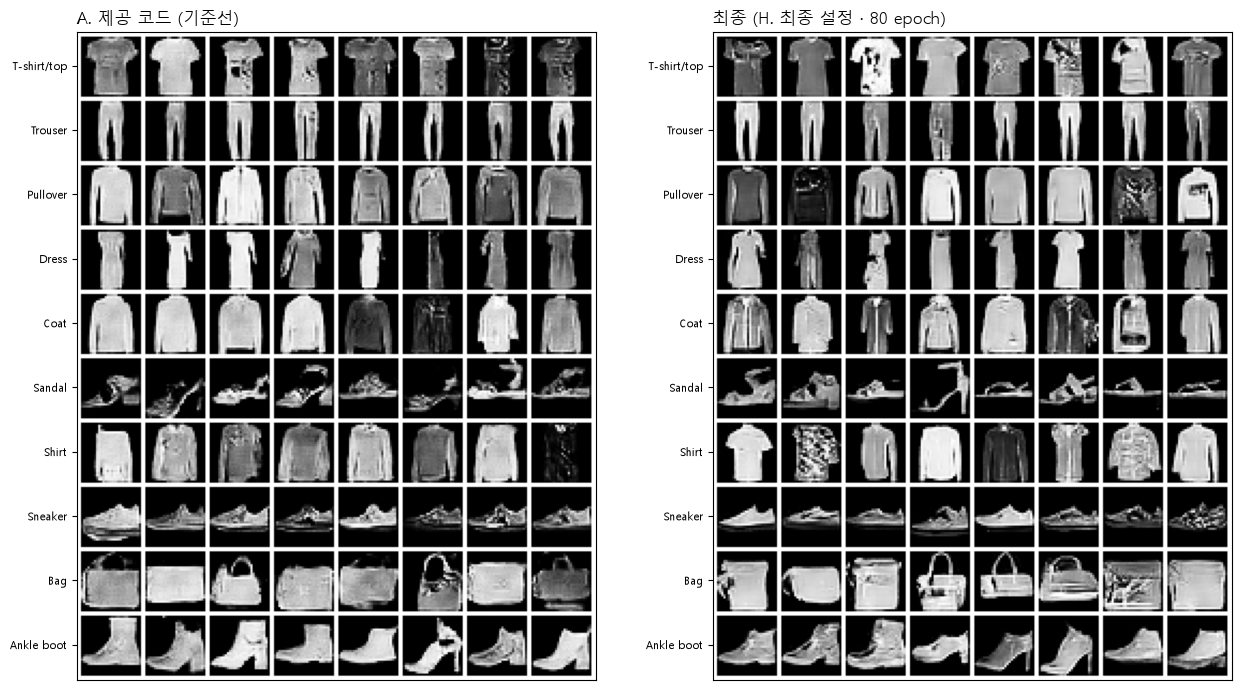

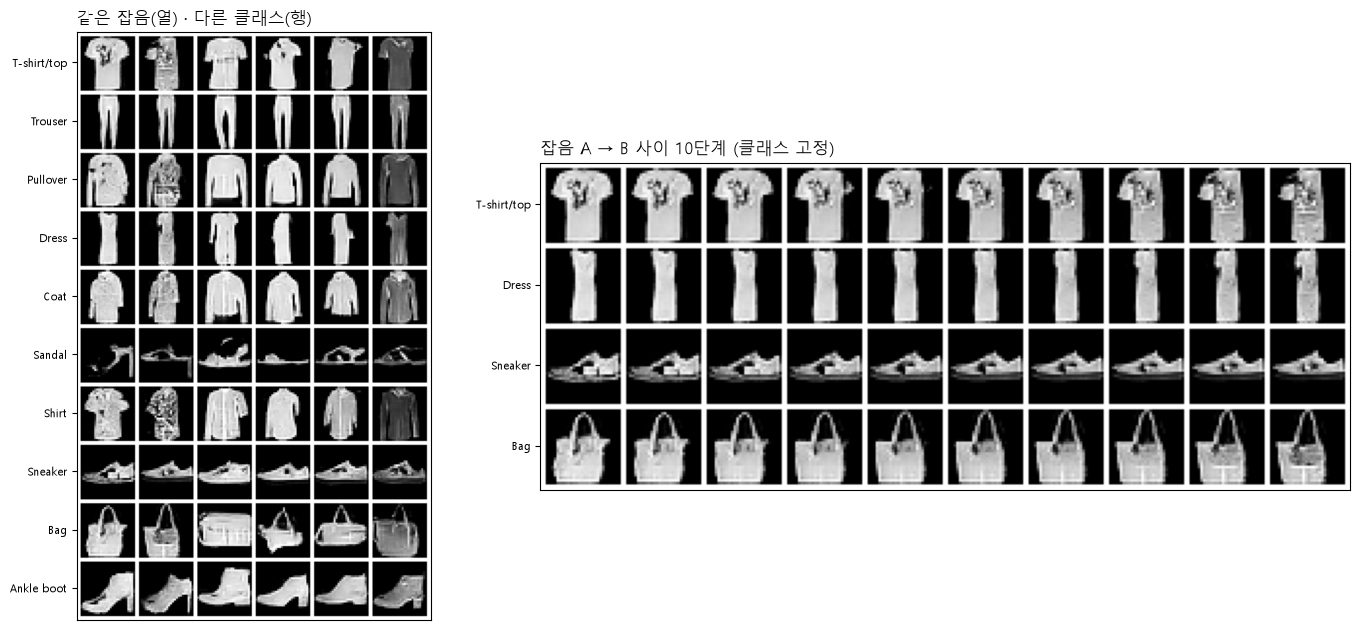

In [22]:
# 같은 잡음 · 같은 클래스: 기준선 vs 최종 (클래스마다 8장)
pick = torch.cat([torch.arange(c * 1000, c * 1000 + 8) for c in range(10)])  # 클래스별 앞 8개
fig, axes = plt.subplots(1, 2, figsize=(13, 7))  # 왼쪽 기준선 · 오른쪽 최종
# 두 모델
for ax, imgs, t in zip(axes, [FAKE_BASE, FAKE_FINAL], ["A. 제공 코드 (기준선)", f"최종 ({FINAL_RUN})"]):
    # 10행 × 8열
    grid = torchvision.utils.make_grid((imgs[pick] + 1) / 2, nrow=8, padding=2, pad_value=1)
    ax.imshow(grid[0], cmap="gray")                                          # 흑백 표시
    ax.set_yticks([15 + 30 * c for c in range(10)], CLASSES, fontsize=8)     # 행 이름
    ax.set_xticks([])                                                        # 가로 눈금 숨김
    ax.set_title(t, loc="left")                                              # 그림 제목
plt.tight_layout()                                                           # 간격 정리
plt.show()                                                                   # 그림 출력

# 같은 잡음 · 클래스만 변경 (잡음 = 스타일, 클래스 = 종류인지 확인)
z_style = torch.randn(6, LATENT, generator=torch.Generator().manual_seed(7))  # 잡음 6개
# 클래스마다 같은 잡음 6개
rows = [generate(G_final, z_style, torch.full((6,), c)) for c in range(10)]
# 10행 × 6열
grid = torchvision.utils.make_grid((torch.cat(rows) + 1) / 2, nrow=6, padding=2, pad_value=1)
# 잡음 두 개 사이를 잇기 (클래스 고정, 10단계)
z_a, z_b = z_style[0], z_style[1]                                          # 양 끝 잡음
steps = torch.linspace(0, 1, 10)[:, None]                                  # 섞는 비율
z_line = (1 - steps) * z_a + steps * z_b                                   # 직선으로 이음
# 4개 클래스
line = torch.cat([generate(G_final, z_line, torch.full((10,), c)) for c in (0, 3, 7, 8)])
grid2 = torchvision.utils.make_grid((line + 1) / 2, nrow=10, padding=2, pad_value=1)  # 4행 × 10열
fig, axes = plt.subplots(1, 2, figsize=(14, 6.4), gridspec_kw={"width_ratios": [6, 10]})  # 두 그림
axes[0].imshow(grid[0], cmap="gray")                                       # 같은 잡음 · 다른 클래스
axes[0].set_yticks([15 + 30 * c for c in range(10)], CLASSES, fontsize=8)  # 행 이름
axes[0].set_title("같은 잡음(열) · 다른 클래스(행)", loc="left")           # 그림 제목
axes[1].imshow(grid2[0], cmap="gray")                                      # 잡음 보간
# 행 이름
axes[1].set_yticks([15 + 30 * k for k in range(4)], [CLASSES[c] for c in (0, 3, 7, 8)], fontsize=8)
axes[1].set_title("잡음 A → B 사이 10단계 (클래스 고정)", loc="left")      # 그림 제목
for ax in axes:                                                            # 두 그림
    ax.set_xticks([])                                                      # 가로 눈금 숨김
plt.tight_layout()                                                         # 간격 정리
plt.show()                                                                 # 그림 출력

**결과 해설**

```
위 그림   같은 잡음 · 같은 클래스로 A와 최종 모델을 8장씩 비교
아래 왼쪽 열마다 같은 잡음 · 행마다 다른 클래스
아래 오른쪽 두 잡음 사이를 10단계로 보간 (클래스 고정)
```

- **위 그림**: 기준선 A는 Coat · Pullover · Bag 행이 밝고 비슷한 회색 덩어리가 반복되고, 최종 모델은 같은 행에 지퍼 · 무늬 · 어두운 옷 · 다양한 가방 모양이 섞임 → 5-1의 recall 상승과 일치
- **스타일 격자**: 같은 열은 클래스가 달라도 밝기 · 무늬 성향이 이어짐 (맨 오른쪽 열은 모든 클래스가 어둡고, 두 번째 열은 무늬가 복잡) → 잡음은 '스타일', 클래스는 '종류'를 맡도록 나뉘어 학습됨
- **보간**: 10단계 모두 해당 클래스의 옷 모양을 유지하며 무늬 · 밝기만 서서히 바뀜 → 잠재 공간이 끊김 없이 이어져 있음 (특정 이미지를 외워 점프하는 모습 없음)

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| utils.make_grid(nrow=, padding=, pad_value=) | torchvision | 여러 장을 격자 한 장으로 | `torchvision.utils.make_grid(..., nrow=8, padding=2, pad_value=1)` |
| full() · linspace() · cat() | torch | 같은 클래스 번호 · 섞는 비율 · 이어 붙이기 | `torch.full((6,), c)` · `torch.linspace(0, 1, 10)[:, None]` |
| subplots(gridspec_kw=) · set_yticks() | matplotlib | 그림 폭 비율 · 행 이름 | `plt.subplots(1, 2, ..., gridspec_kw={"width_ratios": [6, 10]})` |
| zip() | Python 내장 함수 | 축 · 이미지 · 제목 짝 | `zip(axes, [FAKE_BASE, FAKE_FINAL], [...])` |

### 5-4. 다양성과 학습 데이터 외우기 점검

**한글 요약**

- **클래스 안 다양성**: 같은 클래스 생성 이미지끼리의 평균 특징 거리를 실제 test와 나눔 → 1보다 많이 작으면 비슷한 이미지만 만드는 mode collapse
- **외우기**: 생성 이미지마다 가장 가까운 학습 이미지까지 거리를 재고, 실제 test 이미지의 같은 거리와 비교
- 가장 가까운 생성 6장을 학습 이미지와 나란히 확인

**실행 흐름**

1. **입력**: `f_base` · `f_final` · `f_test` · `X_train`
2. **처리**: 클래스별 평균 쌍 거리 비율 → 학습 54,000장 특징 → 최근접 거리 분포 비교 → 가장 가까운 쌍 그림
3. **저장**: `diversity`
4. **출력**: 다양성 비율 표 · 최근접 거리 요약 · 가장 가까운 쌍

,T-shirt/top,Trouser,Pullover,Dress,Coat,Sandal,Shirt,Sneaker,Bag,Ankle boot
기준선 ÷ 실제,0.774,0.862,0.908,0.835,0.878,0.913,0.763,1.000,0.968,0.954
최종 ÷ 실제,0.883,0.947,0.951,0.897,0.972,0.963,0.884,1.048,1.027,0.976


최근접 학습 거리 중앙값: 실제 시험 1.568 · 최종 생성 1.644
실제 시험 하위 1% 거리(0.826)보다 가까운 비율: 시험 1.0% · 최종 생성 0.4%


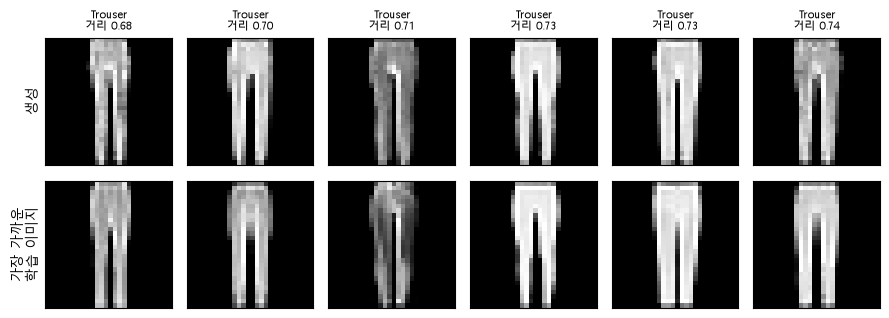

In [23]:
# 클래스 안 다양성: 같은 클래스 이미지끼리 평균 특징 거리 (생성 ÷ 실제, 1에 가까울수록 실제만큼 다양)
def mean_pair_dist(f):                          # 같은 묶음 안 평균 거리
    t = torch.from_numpy(f).float().to(device)  # 특징 텐서
    return torch.pdist(t).mean().item()         # 모든 쌍 평균 거리


diversity = pd.DataFrame({                            # 클래스별 다양성 비율
    "기준선 ÷ 실제": [mean_pair_dist(f_base[TEST_Y.numpy() == c]) / mean_pair_dist(f_test[y_te.numpy() == c])
                 for c in range(10)],
    "최종 ÷ 실제": [mean_pair_dist(f_final[TEST_Y.numpy() == c]) / mean_pair_dist(f_test[y_te.numpy() == c])
                for c in range(10)]}, index=CLASSES)  # 클래스마다
display(diversity.round(3).T)                         # 0.5 아래면 mode collapse 의심

# 학습 데이터 외우기 점검: 가장 가까운 학습 이미지까지 거리 (생성 vs 실제 시험)
f_train = torch.from_numpy(clf_out(X_train)[0]).float().to(device)  # 학습 54,000장 특징


def nearest_train(f):                                 # 가장 가까운 학습 이미지 거리
    # 2,000장씩 최근접 거리
    d = torch.cat([torch.cdist(torch.from_numpy(f[i:i + 2000]).float().to(device), f_train).min(1).values
                   for i in range(0, len(f), 2000)])  # 2,000장씩 최근접 거리
    return d.cpu().numpy()                            # 배열로


d_test, d_final = nearest_train(f_test), nearest_train(f_final)  # 시험 · 최종 생성
thr = np.quantile(d_test, 0.01)                                  # 실제 시험 이미지의 하위 1% 거리
# 분포 가운데 비교
print(f"최근접 학습 거리 중앙값: 실제 시험 {np.median(d_test):.3f} · 최종 생성 {np.median(d_final):.3f}")
# 아주 가까운 비율 비교
print(f"실제 시험 하위 1% 거리({thr:.3f})보다 가까운 비율: 시험 1.0% · 최종 생성 {(d_final < thr).mean():.1%}")

# 가장 가까운 생성 이미지 6장과 그 학습 이미지
idx = np.argsort(d_final)[:6]                            # 거리 최소 6장
# 학습 번호
near = torch.cdist(torch.from_numpy(f_final[idx]).float().to(device), f_train).argmin(1).cpu()
fig, axes = plt.subplots(2, 6, figsize=(9, 3.4))         # 위: 생성 · 아래: 가장 가까운 학습 이미지
for k in range(6):                                       # 6쌍
    axes[0, k].imshow(FAKE_FINAL[idx[k], 0], cmap="gray")  # 생성
    axes[1, k].imshow(X_train[near[k], 0], cmap="gray")  # 학습
    # 클래스 · 거리
    axes[0, k].set_title(f"{CLASSES[TEST_Y[idx[k]]]}\n거리 {d_final[idx[k]]:.2f}", fontsize=8)
for ax in axes.ravel():                                  # 모든 칸
    ax.set_xticks([])                                    # 눈금 숨김
    ax.set_yticks([])                                    # 눈금 숨김
axes[0, 0].set_ylabel("생성")                            # 행 이름
axes[1, 0].set_ylabel("가장 가까운\n학습 이미지")        # 행 이름
plt.tight_layout()                                       # 간격 정리
plt.show()                                               # 그림 출력

**결과 해설**

```
클래스 안 다양성 (생성 ÷ 실제)  기준선 0.763 ~ 1.000 · 최종 0.883 ~ 1.048
가장 낮은 클래스                기준선 Shirt 0.763 · T-shirt/top 0.774 → 최종 0.884 · 0.883
최근접 학습 거리 중앙값          실제 시험 1.568 · 최종 생성 1.644
실제 시험 하위 1% 거리(0.826)보다 가까운 비율  시험 1.0% · 최종 생성 0.4%
```

- **mode collapse 없음**: 모든 클래스가 0.88 이상, 기준선보다 10개 클래스 모두 높아짐 (0.5 아래면 의심 기준)
- **외우기 없음**: 생성 이미지가 학습 이미지에 붙어 있는 정도가 실제 test 이미지보다 오히려 덜함 (중앙값 1.644 > 1.568, 아주 가까운 비율 0.4% < 1.0%)
- 가장 가까운 6쌍은 모두 Trouser: 바지는 모양 변화가 적은 클래스라 어떤 바지든 학습 이미지와 가깝게 나옴. 그림에서 생성 이미지와 학습 이미지의 무늬 · 밝기가 서로 달라 복사가 아님을 눈으로도 확인

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| pdist() · cdist() · argmin() | torch | 모든 쌍 거리 · 최근접 거리 · 위치 | `torch.pdist(t).mean()` · `torch.cdist(...).argmin(1)` |
| quantile() · median() · argsort() | numpy | 하위 1% 거리 · 중앙값 · 가까운 순 | `np.quantile(d_test, 0.01)` · `np.argsort(d_final)[:6]` |
| set_xticks([]) · set_yticks([]) · set_ylabel() | matplotlib | 눈금 숨김 · 행 이름 (생성 · 학습) | `axes[0, 0].set_ylabel("생성")` |
| mean_pair_dist() · nearest_train() | 사용자 정의 함수 | 클래스 안 다양성 · 학습 이미지 최근접 거리 | `mean_pair_dist(f_final[...])` · `nearest_train(f_final)` |

---
## 6. 마무리

### 최종 결과

| 항목 | 결과 |
| :-- | :-- |
| **최종 모델** | Projection 판별자 (BatchNorm) + 넓은 생성자 (파라미터 1,910,629개) · BCE · Adam 2e-4 (0.5, 0.999) · 배치 64 · 80 epoch 중 검증 최고 75 epoch · seed 1 |
| **test** (10,000장, 한 번만 평가) | FID(Inception) **15.53** · FID(분류기) **0.342** · IS 8.61 · 조건 일치율 **0.940** · precision 0.798 · recall **0.478** |
| **기준선** (제공 코드) | FID(Inception) 25.01 · FID(분류기) 1.230 · 조건 일치율 0.924 · recall 0.311 |
| **바닥 기준선** (실제 학습 10,000 vs test) | FID(Inception) 2.73 · FID(분류기) 0.030 · IS 9.10 · recall 0.862 |

### 핵심 결과

- **기준선부터 고정**: 제공 코드를 한 글자도 바꾸지 않은 A를 같은 조건으로 학습 · 평가 → 모든 개선을 같은 잣대로 비교
- **판별자가 클래스를 쓰는 방식이 핵심**: Projection으로 바꾸는 한 가지 변화가 전체 개선의 대부분 (검증 FID(분류기) 1.230 → 0.544)
- **'좋다고 알려진 기법'도 검증**: SN · Hinge · TTUR · betas (0, 0.9)는 모두 기각, 판별자 정답률 곡선으로 '판별자가 너무 약하거나 강해짐'을 확인
- **EDA가 실험을 예측**: 신발 방향 쏠림(1-3) → 반전 증강의 실패(4-8), 상의끼리 유사도 0.98(1-4) → 상의끼리 혼동(5-2)
- **seed 반복이 결론을 뒤집음**: 한 번 비교의 1위(B)와 세 번 평균의 1위(G)가 달랐음
- **남은 과제는 다양성**: precision 0.798은 바닥 기준선(0.861)에 가깝지만 recall 0.478은 0.862와 거리가 큼

### 재현성 확인

같은 코드 · 같은 seed로 전체 노트북을 두 번 실행해 비교. 1차 실행 뒤 바꾼 것은 **IS 계산의 섞기 한 줄**(클래스 순으로 정렬된 묶음을 10조각으로 나눠 조각마다 한 클래스만 들어가던 문제)과 1-3 · 5-4 그림의 행 이름뿐이고, 학습 코드는 같음.

| 항목 | 1차 실행 | 2차 실행 (이 노트북) |
| :-- | :-- | :-- |
| 데이터 탐색 · 분할 · 판정 분류기 (1 ~ 3장) | 검증 정확도 0.9312 · 시험 0.9284 | 같음 |
| 실험 A ~ H 검증 FID(분류기) · FID(Inception) · 조건 일치율 · precision · recall | 예: A 1.2299 · B 0.5439 · H 0.3275 | **소수점 넷째 자리까지 같음** |
| 최종 설정 · 선택된 실행 | G · seed 1 → H (75 epoch) | 같음 |
| test FID(Inception) · FID(분류기) · recall | 15.5290 · 0.3424 · 0.4779 | 같음 |
| 실제 이미지 IS (학습 6,000 vs 검증) | 1.0865 (섞기 전, 잘못된 값) | **9.0892** |
| 학습 시간 (예: C) | 6.6분 | 6.9분 (시간만 다름) |

- **완전히 같은 결과**: cuDNN 결정적 모드 · seed별 데이터 순서 고정 · 고정 평가 잡음 덕분에 GPU 학습 14회가 두 번 모두 같은 값을 냄. 4-11에서 80 epoch 실행의 35 epoch 값이 40 epoch 실행과 같은 것도 같은 원리
- **1차 실행에서 찾은 오류**: 실제 이미지 IS가 1.09로 나와, 최대 10인 지표에서 실제 이미지가 잡음(1.17)보다 낮은 모순 → 원인을 찾아 고친 뒤 실제 9.09 · 잡음 1.17로 정상화. **기준선을 함께 재지 않았다면 놓쳤을 오류**

### 다음 단계

- **다양성(recall) 올리기**: 판별자에 미니배치 표준편차 층 추가, 생성자 쪽 클래스 조건을 BatchNorm 대신 클래스별 정규화(conditional BatchNorm)로 넣어 비교
- **SN · Hinge 재검증**: 판별자 채널을 키워 '판별자가 너무 약해지는' 문제를 없앤 뒤, 같은 기법이 도움이 되는지 다시 확인
- **Sneaker · 상의 경계**: 일치율이 하락한 두 클래스에 대해 판별자 클래스 벡터 간 거리를 확인하고, 클래스 조건 손실(보조 분류기, AC-GAN 방식)을 더해 비교
- **에폭 더 늘리기**: 80 epoch에서도 검증 FID가 천천히 내려가는 중 → 학습률 감소와 함께 120 epoch까지 확인

### 최종 요약표

| 단계 | 한 일 | 핵심 근거 |
| :-- | :-- | :-- |
| **1. 데이터 탐색** | 분포 · 밝기 · 형태 · 방향 · 유사도 · 중복 | 클래스 균등, 신발 한 방향(Sneaker 0.006), 상의끼리 유사도 0.98, 중복 0장 |
| **2. 데이터 준비** | 학습 · 검증 · 시험 분할, [-1, 1] 정규화 | 54,000 · 6,000 · 10,000, 검증 클래스마다 600 |
| **3. 평가 도구** | 판정 분류기 · 6개 지표 · 바닥 · 천장 기준선 | 분류기 검증 0.931, 실제 FID(분류기) 0.040 · 잡음 68.6 |
| **4. 모델과 학습** | 판별자 → 정규화 → 손실 → 옵티마이저 → 증강 → 생성자 → seed → 에폭 | 검증 FID(분류기) 1.230 → 0.544 → (seed 평균) 0.533 → 0.328 |
| **5. test 평가** | 지표 · 클래스별 · 생성 이미지 · 다양성 · 외우기 | FID(Inception) 25.01 → 15.53, recall 0.311 → 0.478, 외우기 0.4% |
| **6. 마무리** | 두 번 실행해 재현성 확인 | 모든 학습 결과 동일, IS 계산 오류 발견 · 수정 |